# Analyse Exploratoire

### Import des modules

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np

#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

from sklearn import datasets, linear_model, svm

#### TERMINER L'ANALYSE EXPLORATOIRE 

A réaliser : 
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

Qelques pistes d'analyse : 

* Identifier les colonnes avec une majorité de valeurs manquantes ou constantes en utilisant la méthode value_counts() de Pandas
* Mettre en evidence les différences entre les immeubles mono et multi-usages
* Utiliser des pairplots et des boxplots pour faire ressortir les outliers ou des batiments avec des valeurs peu cohérentes d'un point de vue métier 

Pour vous inspirer, ou comprendre l'esprit recherché dans une analyse exploratoire, vous pouvez consulter ce notebook en ligne : https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python. Il ne s'agit pas d'un modèle à suivre à la lettre ni d'un template d'analyses attendues pour ce projet. 

In [4]:
building_consumption = pd.read_csv('./2016_Building_Energy_Benchmarking.csv')

In [28]:
# On regarde comment un batiment est défini dans ce jeu de données 
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [29]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type 
building_consumption.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

#### Visualisation des valeurs manquantes

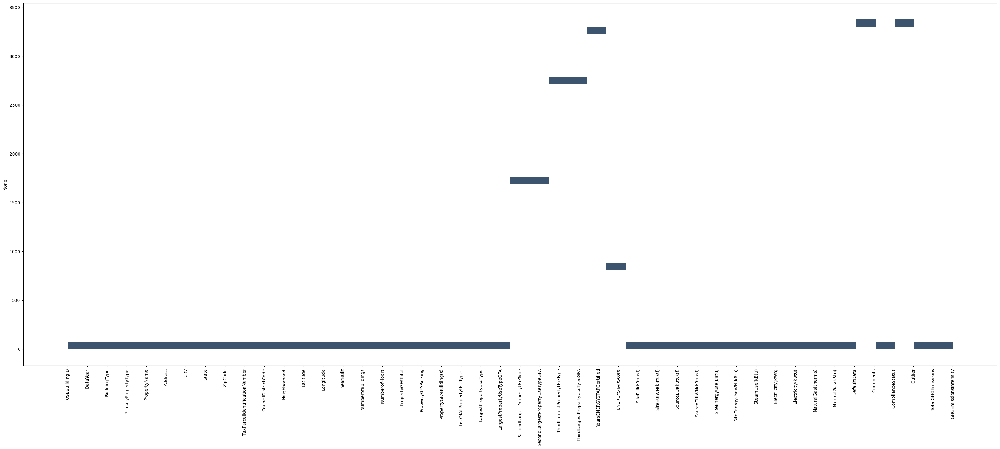

In [ ]:
columns = list(building_consumption)
#print('columns :',columns)  
#sizes = building_consumption.count()
#print('Sizes :',sizes)

#print("is na : ",building_consumption.isna().sum())

chart=plt.figure(figsize=(40, 15))
sns.histplot( x=columns,y=building_consumption.isna().sum(),bins=46,element='step',discrete=False) 
plt.xticks( rotation='vertical')
plt.show()

# for column in columns:
#     chart=plt.figure(figsize=(40, 15))
#     sns.countplot( data=building_consumption.column.fillna('Missing') )
#     plt.xticks( rotation='vertical')

### 1 Valeurs uniques

In [ ]:
# On regarde les valeurs uniques de certaines colonnes

print(f'*************DataYear : ',pd.unique(building_consumption['DataYear'].to_numpy().flatten()))
print(f'*************YearBuilt : ',pd.unique(building_consumption['YearBuilt'].to_numpy().flatten()))
print(f'*************BuildingType : ',pd.unique(building_consumption['BuildingType'].to_numpy().flatten()))
print(f'*************PrimaryPropertyType : ',pd.unique(building_consumption['PrimaryPropertyType'].to_numpy().flatten()))
print(f'*************City : ',pd.unique(building_consumption['City'].to_numpy().flatten()))
print(f'*************Neighborhood : ',pd.unique(building_consumption['Neighborhood'].to_numpy().flatten()))
print(f'*************LargestPropertyUseType : ',pd.unique(building_consumption['LargestPropertyUseType'].to_numpy().flatten()))
print(f'*************ListOfAllPropertyUseTypes : ',pd.unique(building_consumption['ListOfAllPropertyUseTypes'].to_numpy().flatten()))

print(f'*************Comments : ',pd.unique(building_consumption['Comments'].to_numpy().flatten()))
print(f'*************Outlier: ',pd.unique(building_consumption['Outlier'].to_numpy().flatten()))

print(f'*************LargestPropertyUseTypeGFA: ',pd.unique(building_consumption['LargestPropertyUseTypeGFA'].to_numpy().flatten()))
print(f'*************PropertyGFABuilding(s): ',pd.unique(building_consumption['PropertyGFABuilding(s)'].to_numpy().flatten()))


*************DataYear :  [2016]
*************YearBuilt :  [1927 1996 1969 1926 1980 1999 1904 1910 1998 1928 1922 2004 1930 1983
 1907 1916 1985 1961 2001 1991 1955 1978 1949 1989 1906 1994 1992 1990
 1950 1900 1954 1911 1973 1920 1982 1908 1959 2000 1997 1962 1970 2008
 1948 1965 1929 2010 1938 1986 2002 1923 2003 1957 1964 1941 1963 2006
 1915 1958 2009 2011 1971 2007 1951 1953 1952 1960 1937 1966 1968 1925
 1924 2005 1909 1931 1972 1914 1913 1917 1995 1981 1976 1988 1979 1947
 1984 1956 1912 1977 1921 1945 1974 1975 1946 1967 1987 1940 1932 1993
 1918 1905 1902 1939 1944 1942 1903 2012 2013 2015 1901 1919 2014 1936
 1935]
*************BuildingType :  ['NonResidential' 'Nonresidential COS' 'Multifamily MR (5-9)'
 'SPS-District K-12' 'Campus' 'Multifamily LR (1-4)'
 'Multifamily HR (10+)' 'Nonresidential WA']
*************PrimaryPropertyType :  ['Hotel' 'Other' 'Mid-Rise Multifamily' 'Mixed Use Property' 'K-12 School'
 'University' 'Small- and Mid-Sized Office' 'Self-Storage Facility'

**Visualisation des valeurs uniques des 46 colonnes**

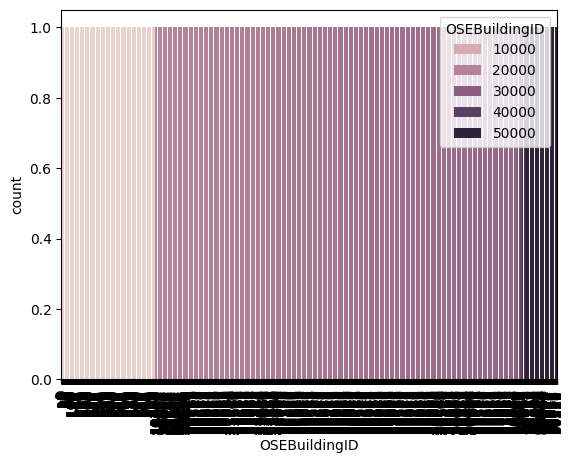

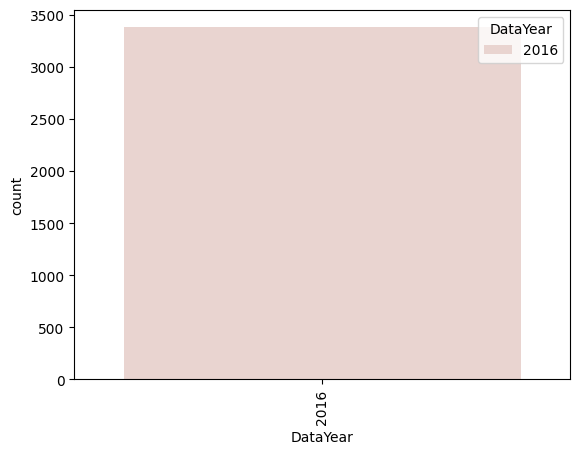

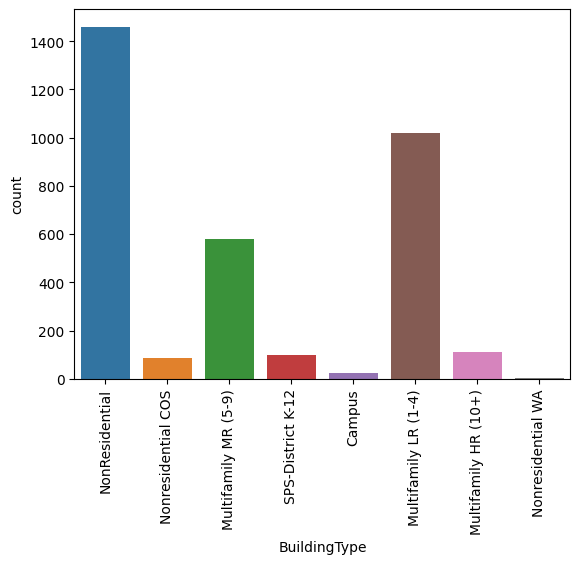

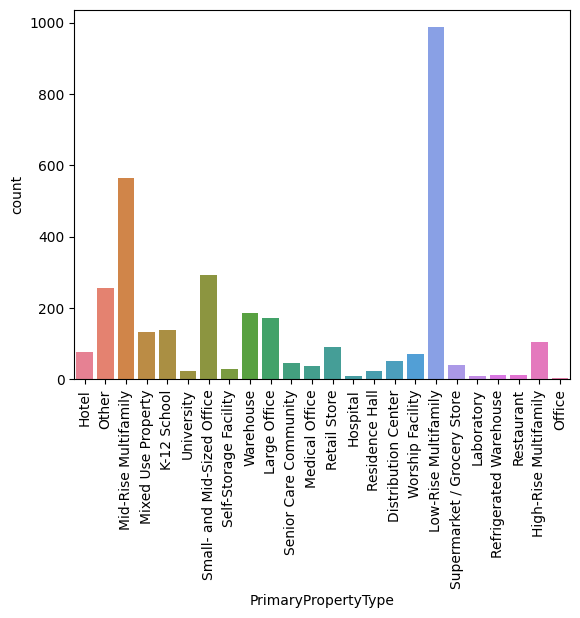

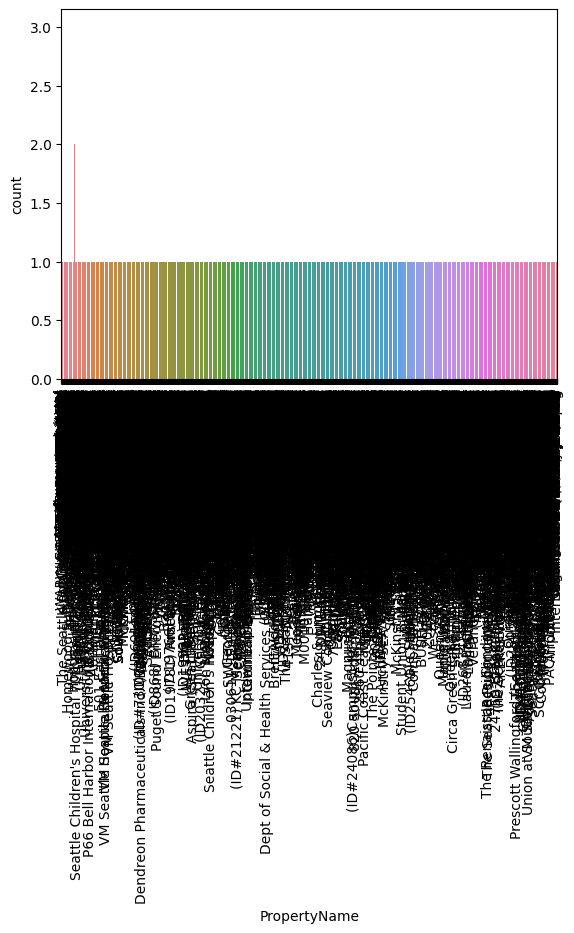

...

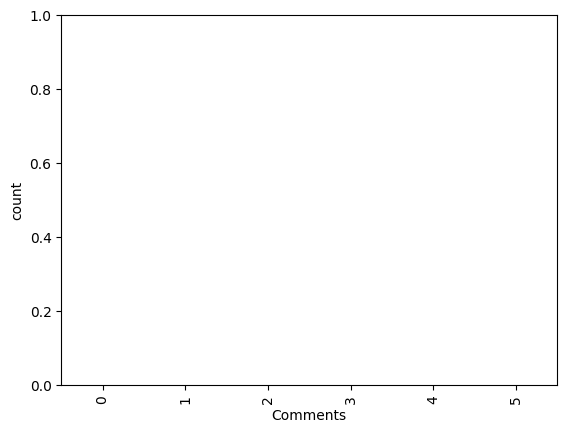

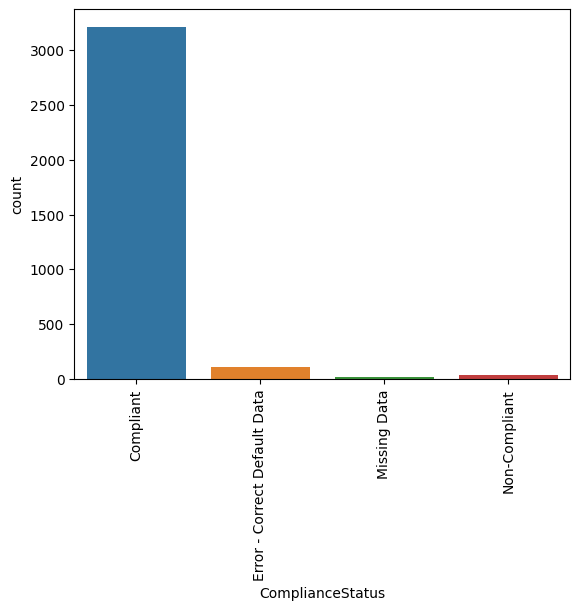

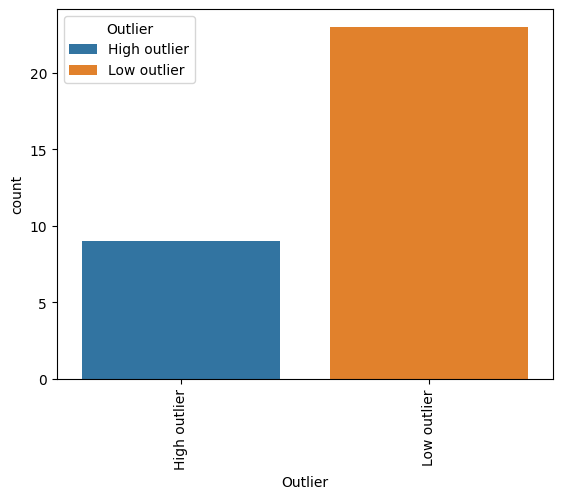

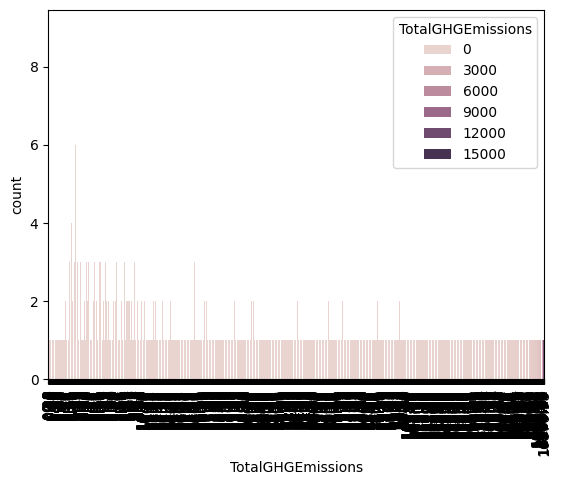

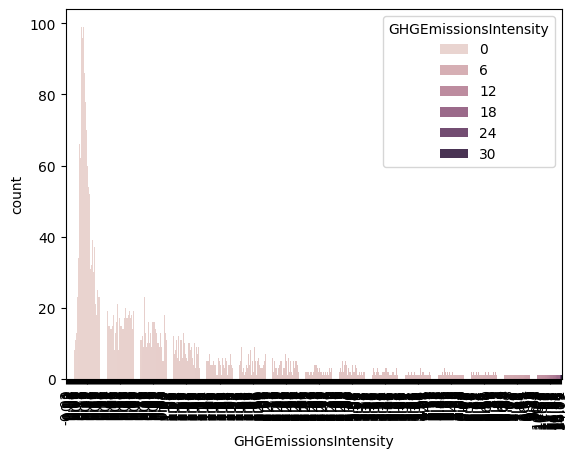

In [ ]:
#afichage des count plots pour chaque colonne
for column in building_consumption:
    my_value = column
    plot=sns.countplot(x=my_value,data=building_consumption,hue=my_value)
    plt.setp(plot.get_xticklabels(), rotation=90)
    plt.show()

#permet de distingué :
#   les catégories constantes commes DataYear ou City...
#   les catégories permettant le tri des batiments comme BuildingType, PrimaryPropertyType, LargestPropertyUseType...
#   les valeurs abérentes comme le nombre d'étages (NumberofFloors) ou la surface (PropertyGFABuilding(s))

### 2 Reccherche des doublons en ID/Nom

In [7]:
for column in building_consumption:
    print('----------------------------------')
    print(f'Colonne : ',building_consumption[column].value_counts())
    

----------------------------------
Colonne :  OSEBuildingID
1        1
2        1
3        1
5        1
8        1
        ..
50222    1
50223    1
50224    1
50225    1
50226    1
Name: count, Length: 3376, dtype: int64
----------------------------------
Colonne :  DataYear
2016    3376
Name: count, dtype: int64
----------------------------------
Colonne :  BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64
----------------------------------
Colonne :  PrimaryPropertyType
Low-Rise Multifamily           987
Mid-Rise Multifamily           564
Small- and Mid-Sized Office    293
Other                          256
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             133
High-Rise Multifamily 

In [81]:
print(f'Colonne : ',building_consumption['OSEBuildingID'].value_counts()) 

Colonne :  OSEBuildingID
1        1
2        1
3        1
5        1
8        1
        ..
50222    1
50223    1
50224    1
50225    1
50226    1
Name: count, Length: 3376, dtype: int64


#### 2.1 Par Nom

In [111]:
b1 = building_consumption[building_consumption['PropertyName']=='Northgate Plaza']
print( b1.to_string())    


      OSEBuildingID  DataYear          BuildingType    PrimaryPropertyType     PropertyName           Address     City State  ZipCode TaxParcelIdentificationNumber  CouncilDistrictCode Neighborhood  Latitude  Longitude  YearBuilt  NumberofBuildings  NumberofFloors  PropertyGFATotal  PropertyGFAParking  PropertyGFABuilding(s)                      ListOfAllPropertyUseTypes LargestPropertyUseType  LargestPropertyUseTypeGFA SecondLargestPropertyUseType  SecondLargestPropertyUseTypeGFA ThirdLargestPropertyUseType  ThirdLargestPropertyUseTypeGFA YearsENERGYSTARCertified  ENERGYSTARScore  SiteEUI(kBtu/sf)  SiteEUIWN(kBtu/sf)  SourceEUI(kBtu/sf)  SourceEUIWN(kBtu/sf)  SiteEnergyUse(kBtu)  SiteEnergyUseWN(kBtu)  SteamUse(kBtu)  Electricity(kWh)  Electricity(kBtu)  NaturalGas(therms)  NaturalGas(kBtu)  DefaultData  Comments ComplianceStatus Outlier  TotalGHGEmissions  GHGEmissionsIntensity
323             460      2016        NonResidential           Large Office  Northgate Plaza   9709 3rd Ave 

In [112]:
b1 = building_consumption[building_consumption['PropertyName']=='South Park']
print( b1.to_string())    

      OSEBuildingID  DataYear    BuildingType PrimaryPropertyType PropertyName          Address     City State  ZipCode TaxParcelIdentificationNumber  CouncilDistrictCode      Neighborhood  Latitude  Longitude  YearBuilt  NumberofBuildings  NumberofFloors  PropertyGFATotal  PropertyGFAParking  PropertyGFABuilding(s)                                        ListOfAllPropertyUseTypes      LargestPropertyUseType  LargestPropertyUseTypeGFA SecondLargestPropertyUseType  SecondLargestPropertyUseTypeGFA ThirdLargestPropertyUseType  ThirdLargestPropertyUseTypeGFA YearsENERGYSTARCertified  ENERGYSTARScore  SiteEUI(kBtu/sf)  SiteEUIWN(kBtu/sf)  SourceEUI(kBtu/sf)  SourceEUIWN(kBtu/sf)  SiteEnergyUse(kBtu)  SiteEnergyUseWN(kBtu)  SteamUse(kBtu)  Electricity(kWh)  Electricity(kBtu)  NaturalGas(therms)  NaturalGas(kBtu)  DefaultData  Comments ComplianceStatus Outlier  TotalGHGEmissions  GHGEmissionsIntensity
162             261      2016          Campus        Large Office   South Park   1420 S Trent

In [113]:
b1 = building_consumption[building_consumption['PropertyName']=='Garden Court Apartments']
print( b1.to_string())    

      OSEBuildingID  DataYear          BuildingType   PrimaryPropertyType             PropertyName                    Address     City State  ZipCode TaxParcelIdentificationNumber  CouncilDistrictCode Neighborhood  Latitude  Longitude  YearBuilt  NumberofBuildings  NumberofFloors  PropertyGFATotal  PropertyGFAParking  PropertyGFABuilding(s)     ListOfAllPropertyUseTypes LargestPropertyUseType  LargestPropertyUseTypeGFA SecondLargestPropertyUseType  SecondLargestPropertyUseTypeGFA ThirdLargestPropertyUseType  ThirdLargestPropertyUseTypeGFA YearsENERGYSTARCertified  ENERGYSTARScore  SiteEUI(kBtu/sf)  SiteEUIWN(kBtu/sf)  SourceEUI(kBtu/sf)  SourceEUIWN(kBtu/sf)  SiteEnergyUse(kBtu)  SiteEnergyUseWN(kBtu)  SteamUse(kBtu)  Electricity(kWh)  Electricity(kBtu)  NaturalGas(therms)  NaturalGas(kBtu)  DefaultData  Comments              ComplianceStatus Outlier  TotalGHGEmissions  GHGEmissionsIntensity
905           20198      2016  Multifamily LR (1-4)  Low-Rise Multifamily  Garden Court Apartme

##### 2.1.1 affichage de tous les doublons de Nom

In [ ]:
building_consumption.value_counts(normalize=True, subset=['PropertyName'])
for PropertyName in enumerate(building_consumption['PropertyName'].value_counts().index.tolist()):
    count = building_consumption[building_consumption['PropertyName']==PropertyName[1]]['PropertyName'].value_counts()[PropertyName[1]]
    
    if(count>1):
        #print('PropertyName :', PropertyName[1],'Counts :',count)
        b1 = building_consumption[building_consumption['PropertyName']==PropertyName[1]]
        print( 'Counts :',count,b1[['PropertyName','BuildingType','LargestPropertyUseType']].to_string())  
    # .value_counts().index.tolist()[0])
    #building_consumption[(building_consumption['OSEBuildingID']==OSEBuildingID).value_counts()].index.tolist()[1])
    #print('idx :', idx)


Counts : 3          PropertyName          BuildingType LargestPropertyUseType
323   Northgate Plaza        NonResidential                 Office
1644  Northgate Plaza  Multifamily LR (1-4)  Senior Care Community
2609  Northgate Plaza  Multifamily LR (1-4)    Multifamily Housing
Counts : 2      PropertyName    BuildingType      LargestPropertyUseType
162    South Park          Campus                      Office
1462   South Park  NonResidential  Non-Refrigerated Warehouse
Counts : 2                  PropertyName          BuildingType LargestPropertyUseType
905   Garden Court Apartments  Multifamily LR (1-4)    Multifamily Housing
1574  Garden Court Apartments  Multifamily LR (1-4)    Multifamily Housing
Counts : 2      PropertyName          BuildingType LargestPropertyUseType
1272     Fairview        NonResidential                 Office
1800     Fairview  Multifamily MR (5-9)    Multifamily Housing
Counts : 2         PropertyName    BuildingType      LargestPropertyUseType
1158  Canal 

##### 2.1.1.1 Constat:
Beaucoup de doublons sont des usages multiples

    - office
    - warehouse
    - piscine
    - logement

##### 2.1.2 Affichage de tous les doublons d'Id

In [ ]:
building_consumption.value_counts(normalize=True, subset=['OSEBuildingID'])
for OSEBuildingID in enumerate(building_consumption['OSEBuildingID'].value_counts().index.tolist()):
    count = building_consumption[building_consumption['OSEBuildingID']==OSEBuildingID[1]]['OSEBuildingID'].value_counts()[OSEBuildingID[1]]
    #print('OSEBuildingID :', OSEBuildingID[1],'Counts :',count)
    if(count>1):
        #print('PropertyName :', PropertyName[1],'Counts :',count)
        b1 = building_consumption[building_consumption['OSEBuildingID']==OSEBuildingID[1]]
        print( 'Counts :',count,b1[['OSEBuildingID','PropertyName','BuildingType','LargestPropertyUseType']].to_string())  

OSEBuildingID : 1 Counts : 1
OSEBuildingID : 2 Counts : 1
OSEBuildingID : 3 Counts : 1
OSEBuildingID : 5 Counts : 1
OSEBuildingID : 8 Counts : 1
OSEBuildingID : 9 Counts : 1
OSEBuildingID : 10 Counts : 1
OSEBuildingID : 11 Counts : 1
OSEBuildingID : 12 Counts : 1
OSEBuildingID : 13 Counts : 1
OSEBuildingID : 15 Counts : 1
OSEBuildingID : 16 Counts : 1
OSEBuildingID : 17 Counts : 1
OSEBuildingID : 18 Counts : 1
OSEBuildingID : 19 Counts : 1
OSEBuildingID : 21 Counts : 1
OSEBuildingID : 22 Counts : 1
OSEBuildingID : 23 Counts : 1
OSEBuildingID : 24 Counts : 1
OSEBuildingID : 25 Counts : 1
OSEBuildingID : 26 Counts : 1
OSEBuildingID : 27 Counts : 1
OSEBuildingID : 28 Counts : 1
OSEBuildingID : 29 Counts : 1
OSEBuildingID : 30 Counts : 1
OSEBuildingID : 31 Counts : 1
OSEBuildingID : 32 Counts : 1
OSEBuildingID : 33 Counts : 1
OSEBuildingID : 34 Counts : 1
OSEBuildingID : 35 Counts : 1
OSEBuildingID : 36 Counts : 1
OSEBuildingID : 37 Counts : 1
OSEBuildingID : 38 Counts : 1
OSEBuildingID : 

##### 2.1.2.1 Constat:
Aucun doublons d'ID

### 3.1 Recherche de filtre sur la partie Résidentielle / Non Résidentielle

In [ ]:
building_consumption[building_consumption['BuildingType']=='NonResidential']#1460

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3338,50068,2016,NonResidential,Warehouse,Airport - Maintenance Shop - DOT: KCIA,6518 Ellis,Seattle,WA,98108.0,2824049007,...,2.147724e+05,732803.0,28730.51953,2873052.0,False,NaN,Compliant,NaN,157.70,3.03
3339,50069,2016,NonResidential,Small- and Mid-Sized Office,Airport - Main Terminal,7277 Perimeter Rd.,Seattle,WA,98108.0,2824049007,...,6.351199e+05,2167029.0,22536.21094,2253621.0,False,NaN,Compliant,NaN,134.80,5.39
3340,50070,2016,NonResidential,Other,Tennis Center Sand Point,7135 Sportsfield Drive NE,Seattle,WA,98155.0,0225049062,...,5.573329e+05,1901620.0,10241.59961,1024160.0,False,NaN,Compliant,NaN,67.65,0.94
3347,50081,2016,NonResidential,K-12 School,Hamlin Robinson School,1701 20th Ave South,Seattle,WA,98144.0,7548300840,...,3.886204e+05,1325973.0,0.00000,0.0,False,NaN,Compliant,NaN,9.24,0.21


In [ ]:
building_consumption[building_consumption['BuildingType']=='Nonresidential COS']#85

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
5,9,2016,Nonresidential COS,Other,West Precinct,810 Virginia St,Seattle,WA,98101.0,0660000560,...,2.160444e+06,7.371434e+06,47151.816410,4.715182e+06,False,NaN,Compliant,NaN,301.81,3.10
15,21,2016,Nonresidential COS,Other,The Seattle Public Library - Central Library,1000 Fourth Avenue,Seattle,WA,98154.0,0942000275,...,5.231916e+06,1.785130e+07,0.000000,0.000000e+00,False,NaN,Compliant,NaN,181.38,0.44
69,103,2016,Nonresidential COS,Other,Key Arena,334 1st Ave. N,Seattle,WA,98109.0,1985200003,...,4.226010e+06,1.441915e+07,6886.799805,6.886800e+05,False,NaN,Compliant,NaN,607.41,1.56
70,104,2016,Nonresidential COS,Other,Bagley Wright Theatre,151 Mercer St.,Seattle,WA,98109.0,1985200003,...,1.100268e+06,3.754115e+06,0.000000,0.000000e+00,False,NaN,Compliant,NaN,344.20,3.77
71,106,2016,Nonresidential COS,Other,Armory,305 Harrison St.,Seattle,WA,98109.0,1985200305,...,2.125535e+06,7.252325e+06,0.000000,0.000000e+00,False,NaN,Compliant,NaN,804.20,2.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,50222,2016,Nonresidential COS,Office,Horticulture building,1600 S Dakota St,Seattle,WA,NaN,1624049080,...,1.536550e+05,5.242709e+05,3254.750244,3.254750e+05,True,NaN,Error - Correct Default Data,NaN,20.94,1.70
3372,50223,2016,Nonresidential COS,Other,International district/Chinatown CC,719 8th Ave S,Seattle,WA,NaN,3558300000,...,1.162210e+05,3.965461e+05,5537.299805,5.537300e+05,False,NaN,Compliant,NaN,32.17,2.01
3373,50224,2016,Nonresidential COS,Other,Queen Anne Pool,1920 1st Ave W,Seattle,WA,NaN,1794501150,...,5.252517e+05,1.792159e+06,39737.390630,3.973739e+06,False,NaN,Compliant,NaN,223.54,16.99
3374,50225,2016,Nonresidential COS,Mixed Use Property,South Park Community Center,8319 8th Ave S,Seattle,WA,NaN,7883603155,...,1.022480e+05,3.488702e+05,3706.010010,3.706010e+05,False,NaN,Compliant,NaN,22.11,1.57


In [ ]:
building_consumption[building_consumption['BuildingType']=='Nonresidential WA']#1

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
3359,50101,2016,Nonresidential WA,University,Burke Museum,4331 Memorial Way NE,Seattle,WA,98195.0,1625049001,...,932244.6875,3180819.0,0.0,0.0,False,NaN,Compliant,NaN,22.17,0.33


In [ ]:
building_consumption[building_consumption['BuildingType']=='SPS-District K-12']#96

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
22,28,2016,SPS-District K-12,K-12 School,Graham Hill Elementary,5149 S. Graham St.,Seattle,WA,98118.0,1102000138,...,274605.9063,936955.0,6025.229004,602523.0,True,NaN,Error - Correct Default Data,NaN,38.53,0.69
28,34,2016,SPS-District K-12,K-12 School,Meany Building,301/300 21st Ave. E.,Seattle,WA,98112.0,0688000090,...,0.0000,0.0,0.000000,0.0,False,NaN,Missing Data,NaN,0.00,0.00
30,36,2016,SPS-District K-12,K-12 School,Jane Addams Middle,11051 34th Ave. N.E.,Seattle,WA,98125.0,0752000170,...,570809.1875,1947601.0,48315.718750,4831572.0,True,NaN,Error - Correct Default Data,NaN,270.18,1.68
31,37,2016,SPS-District K-12,K-12 School,John Hay Elementary,201 Garfield St.,Seattle,WA,98109.0,0809000005,...,438691.6875,1496816.0,0.000000,0.0,False,NaN,Missing Data,NaN,10.43,0.20
37,50,2016,SPS-District K-12,K-12 School,Lawton Elementary,4000 27th Ave. W.,Seattle,WA,98199.0,0369000400,...,356855.0000,1217589.0,4326.897461,432690.0,False,NaN,Compliant,NaN,31.47,0.57
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2894,27365,2016,SPS-District K-12,K-12 School,Adams Elementary,6110 28th Ave. N.W.,Seattle,WA,98107.0,6658000060,...,464943.9063,1586389.0,0.000000,0.0,True,NaN,Error - Correct Default Data,NaN,11.06,0.19
2944,27597,2016,SPS-District K-12,K-12 School,Northgate Elementary,11725 1st Ave. N.E.,Seattle,WA,98125.0,6411600312,...,230648.0938,786971.0,11938.537110,1193854.0,True,NaN,Error - Correct Default Data,NaN,68.89,1.52
3036,27955,2016,SPS-District K-12,K-12 School,Montlake Elementary,2409 22nd Ave. E.,Seattle,WA,98112.0,6788200735,...,127941.0000,436535.0,8220.842773,822084.0,True,NaN,Error - Correct Default Data,NaN,46.70,1.71
3126,39332,2016,SPS-District K-12,K-12 School,South Shore K-8,4800 S. Henderson,Seattle,WA,98118.0,2123700250,...,880538.0000,3004396.0,19549.021480,1954902.0,True,NaN,Error - Correct Default Data,NaN,124.77,0.90


In [ ]:
building_consumption[building_consumption['BuildingType']=='Campus']#24

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
35,43,2016,Campus,Mixed Use Property,Plant 2 Site,7755 E MARGINAL WAY S,Seattle,WA,98108.0,0022000005,...,4.410208e+07,150476283.0,2.979090e+06,297909000.0,False,NaN,Compliant,NaN,16870.98,34.09
105,172,2016,Campus,University,SSCC MAIN CAMPUS,6000 16th Ave SW,Seattle,WA,98106.0,6171900005,...,7.419278e+06,25314575.0,1.298717e+05,12987166.0,False,NaN,Compliant,NaN,866.23,1.96
128,211,2016,Campus,University,NSCC MAIN CAMPUS,9600 COLLEGE WAY N,Seattle,WA,98103.0,3226049021,...,9.803878e+06,33450832.0,2.440648e+04,2440648.0,False,NaN,Compliant,NaN,362.82,0.52
162,261,2016,Campus,Large Office,South Park,1420 S Trenton,Seattle,WA,98108.0,7883608601,...,1.328294e+07,45321378.0,8.145300e+04,8145300.0,False,NaN,Compliant,NaN,748.55,2.24
195,315,2016,Campus,Other,P66 Bell Harbor International Conference Cente...,2225 Alaskan Way,Seattle,WA,98125.0,7666202325,...,4.041282e+06,13788853.0,1.022892e+05,10228916.0,False,NaN,Compliant,NaN,639.39,2.97
289,419,2016,Campus,Mixed Use Property,Main Market,1501 Pike Place,Seattle,WA,98101.0,1976200205,...,3.031867e+06,10344729.0,4.595774e+04,4595774.0,False,NaN,Compliant,NaN,316.20,2.30
301,432,2016,Campus,Mixed Use Property,Securities Building Campus,1904 Third Avenue,Seattle,WA,98101.0,1977201315,...,4.946370e+06,16877013.0,0.000000e+00,0.0,False,NaN,Compliant,NaN,418.90,1.62
340,477,2016,Campus,Other,Weintraub/Hutchinson/Thomas,1100 Fairview Ave N,Seattle,WA,98109.0,1984200455,...,1.894122e+07,64627449.0,6.674642e+05,66746425.0,False,NaN,Compliant,NaN,3995.45,7.45
661,19491,2016,Campus,Other,Pacific Multiforms Inc- Campus,6606 Urusla Pl. South,Seattle,WA,98155.0,0005200056,...,1.049298e+05,358020.0,1.864077e+04,1864077.0,False,NaN,Compliant,NaN,101.50,4.45
954,20325,2016,Campus,K-12 School,University Prep Academy,8000 25th Ave NE,Seattle,WA,98115.0,1513800010,...,9.694292e+05,3307692.0,3.381491e+04,3381491.0,False,NaN,Compliant,NaN,202.65,9.43


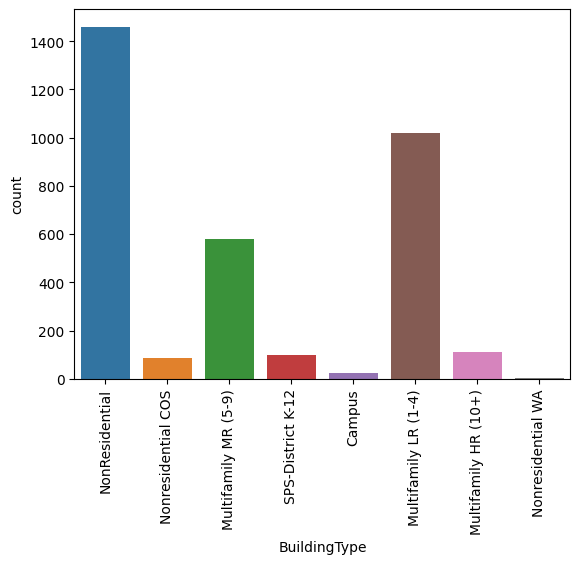

In [57]:
my_value = 'BuildingType'
plot = sns.countplot(x=my_value,data=building_consumption,hue=my_value)
plt.setp(plot.get_xticklabels(), rotation=90)
plt.show()

### tests

##### test 1 bâtiments non destinés à l’habitation :
**Combinaison**: Campus,école,non résidentiel('','WA','COS')

In [5]:
#Test Filtre les batiments non destinés à l’habitation
non_res_building = building_consumption[(building_consumption['BuildingType']=='Campus')|( building_consumption['BuildingType']=='SPS-District K-12')|( building_consumption['BuildingType']=='Nonresidential WA')|( building_consumption['BuildingType']=='Nonresidential COS')|( building_consumption['BuildingType']=='NonResidential')]
non_res_building #1668

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3.946027e+06,12764.529300,1.276453e+06,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3.242851e+06,51450.816410,5.145082e+06,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,4.952666e+07,14938.000000,1.493800e+06,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2.768924e+06,18112.130860,1.811213e+06,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5.368607e+06,88039.984380,8.803998e+06,False,NaN,Compliant,NaN,505.01,2.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,50222,2016,Nonresidential COS,Office,Horticulture building,1600 S Dakota St,Seattle,WA,NaN,1624049080,...,1.536550e+05,5.242709e+05,3254.750244,3.254750e+05,True,NaN,Error - Correct Default Data,NaN,20.94,1.70
3372,50223,2016,Nonresidential COS,Other,International district/Chinatown CC,719 8th Ave S,Seattle,WA,NaN,3558300000,...,1.162210e+05,3.965461e+05,5537.299805,5.537300e+05,False,NaN,Compliant,NaN,32.17,2.01
3373,50224,2016,Nonresidential COS,Other,Queen Anne Pool,1920 1st Ave W,Seattle,WA,NaN,1794501150,...,5.252517e+05,1.792159e+06,39737.390630,3.973739e+06,False,NaN,Compliant,NaN,223.54,16.99
3374,50225,2016,Nonresidential COS,Mixed Use Property,South Park Community Center,8319 8th Ave S,Seattle,WA,NaN,7883603155,...,1.022480e+05,3.488702e+05,3706.010010,3.706010e+05,False,NaN,Compliant,NaN,22.11,1.57


#### test 2 bâtiments non destinés à l’habitation :
Multi usage ne contenant pas Multifamily Housing

In [ ]:
building_consumption[building_consumption["ListOfAllPropertyUseTypes"].str.contains('Multifamily Housing')==False]
#1660 sans 

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3.946027e+06,12764.529300,1.276453e+06,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3.242851e+06,51450.816410,5.145082e+06,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,4.952666e+07,14938.000000,1.493800e+06,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2.768924e+06,18112.130860,1.811213e+06,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5.368607e+06,88039.984380,8.803998e+06,False,NaN,Compliant,NaN,505.01,2.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,50222,2016,Nonresidential COS,Office,Horticulture building,1600 S Dakota St,Seattle,WA,NaN,1624049080,...,1.536550e+05,5.242709e+05,3254.750244,3.254750e+05,True,NaN,Error - Correct Default Data,NaN,20.94,1.70
3372,50223,2016,Nonresidential COS,Other,International district/Chinatown CC,719 8th Ave S,Seattle,WA,NaN,3558300000,...,1.162210e+05,3.965461e+05,5537.299805,5.537300e+05,False,NaN,Compliant,NaN,32.17,2.01
3373,50224,2016,Nonresidential COS,Other,Queen Anne Pool,1920 1st Ave W,Seattle,WA,NaN,1794501150,...,5.252517e+05,1.792159e+06,39737.390630,3.973739e+06,False,NaN,Compliant,NaN,223.54,16.99
3374,50225,2016,Nonresidential COS,Mixed Use Property,South Park Community Center,8319 8th Ave S,Seattle,WA,NaN,7883603155,...,1.022480e+05,3.488702e+05,3706.010010,3.706010e+05,False,NaN,Compliant,NaN,22.11,1.57


In [ ]:
p_avec = building_consumption[building_consumption["PrimaryPropertyType"].str.contains('Multifamily')==True]
#1656 avec
p_sans = building_consumption[building_consumption["PrimaryPropertyType"].str.contains('Multifamily')==False]
#1720 sans
print('Avec Multifamily Housing :',len(p_avec))
print('Sans Multifamily Housing :',len(p_sans))

Avec Multifamily Housing : 1656
Sans Multifamily Housing : 1720


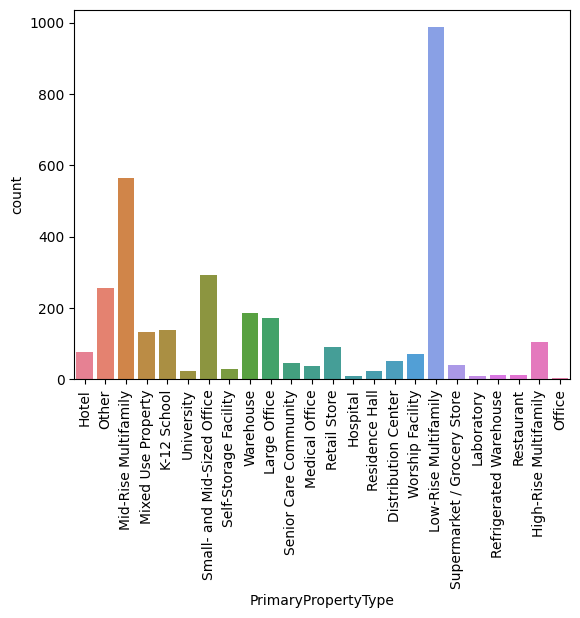

In [41]:
my_value = 'PrimaryPropertyType'
plot = sns.countplot(x=my_value,data=building_consumption,hue=my_value)
plt.setp(plot.get_xticklabels(), rotation=90)
plt.show()

In [43]:
building_consumption[building_consumption["LargestPropertyUseType"].str.contains('Multifamily Housing')==True]
#1667 avec
building_consumption[building_consumption["LargestPropertyUseType"].str.contains('Multifamily Housing')==False]
#1689 sans

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3.946027e+06,12764.529300,1.276453e+06,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3.242851e+06,51450.816410,5.145082e+06,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,4.952666e+07,14938.000000,1.493800e+06,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2.768924e+06,18112.130860,1.811213e+06,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5.368607e+06,88039.984380,8.803998e+06,False,NaN,Compliant,NaN,505.01,2.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,50222,2016,Nonresidential COS,Office,Horticulture building,1600 S Dakota St,Seattle,WA,NaN,1624049080,...,1.536550e+05,5.242709e+05,3254.750244,3.254750e+05,True,NaN,Error - Correct Default Data,NaN,20.94,1.70
3372,50223,2016,Nonresidential COS,Other,International district/Chinatown CC,719 8th Ave S,Seattle,WA,NaN,3558300000,...,1.162210e+05,3.965461e+05,5537.299805,5.537300e+05,False,NaN,Compliant,NaN,32.17,2.01
3373,50224,2016,Nonresidential COS,Other,Queen Anne Pool,1920 1st Ave W,Seattle,WA,NaN,1794501150,...,5.252517e+05,1.792159e+06,39737.390630,3.973739e+06,False,NaN,Compliant,NaN,223.54,16.99
3374,50225,2016,Nonresidential COS,Mixed Use Property,South Park Community Center,8319 8th Ave S,Seattle,WA,NaN,7883603155,...,1.022480e+05,3.488702e+05,3706.010010,3.706010e+05,False,NaN,Compliant,NaN,22.11,1.57


In [42]:
building_consumption[building_consumption["SecondLargestPropertyUseType"].str.contains('Multifamily Housing')==False]
#1661 sans
building_consumption[building_consumption["SecondLargestPropertyUseType"].str.contains('Multifamily Housing')==True]
#18 contenant du multifamily housing en second use type

building_consumption[building_consumption["ThirdLargestPropertyUseType"].str.contains('Multifamily Housing')==False]
#584 sans
building_consumption[building_consumption["ThirdLargestPropertyUseType"].str.contains('Multifamily Housing')==True]
#12 avec

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
289,419,2016,Campus,Mixed Use Property,Main Market,1501 Pike Place,Seattle,WA,98101.0,1976200205,...,3.031867e+06,10344729.0,45957.738280,4595774.0,False,NaN,Compliant,NaN,316.20,2.30
440,601,2016,NonResidential,Mixed Use Property,Wallingford Center,1815 N 45th St.,Seattle,WA,98103.0,4083300140,...,7.545519e+05,2574531.0,8671.120117,867112.0,False,NaN,Compliant,NaN,64.00,1.21
466,627,2016,NonResidential,Small- and Mid-Sized Office,Roebling Building,901 Occidental Ave S,Seattle,WA,98134.0,7666206640,...,3.377417e+05,1152375.0,6240.369629,624037.0,False,NaN,Compliant,NaN,41.18,0.70
612,817,2016,NonResidential,Mixed Use Property,Russell Hall,1414 NE 42nd Street,Seattle,WA,98105.0,1142001150,...,1.137191e+06,3880094.0,9854.570313,985457.0,False,NaN,Compliant,NaN,79.39,0.65
1328,21533,2016,NonResidential,Mixed Use Property,Hyatt Place,110 6th Ave N,Seattle,WA,98109.0,1991200695,...,1.689621e+06,5764988.0,33905.789060,3390579.0,False,NaN,Compliant,NaN,220.26,0.80
1599,22684,2016,NonResidential,Mixed Use Property,Murphy Ballard Building,1903 NW Market St,Seattle,WA,98107.0,2767703630,...,2.877015e+05,981638.0,10134.939450,1013494.0,False,NaN,Compliant,NaN,60.67,2.24
2398,25528,2016,NonResidential,Large Office,Waterfront Place,1011 Western Ave,Seattle,WA,98104.0,9195900000,...,2.788050e+06,9512827.0,0.000000,0.0,False,NaN,Compliant,NaN,66.32,0.22
2506,25886,2016,NonResidential,Small- and Mid-Sized Office,H2125 - Western Triangle,2125 Western Avenue,Seattle,WA,98121.0,9292600000,...,4.334640e+05,1478979.0,0.000000,0.0,False,NaN,Compliant,NaN,10.31,0.22
2759,26847,2016,NonResidential,Small- and Mid-Sized Office,KOBE PARK BUILDING,622 S Washington St,Seattle,WA,98104.0,5247802080,...,4.219145e+05,1439572.0,0.000000,0.0,False,NaN,Compliant,NaN,10.04,0.32
3134,40348,2016,NonResidential,Mixed Use Property,Broadway Market,401 Broadway E,Seattle,WA,98102.0,6850700316 and 6850700315,...,7.488097e+05,2554939.0,2079.069824,207907.0,False,NaN,Compliant,NaN,28.85,0.20


#### test 3 bâtiments non destinés à l’habitation :
Combinaison par bloc de **Multi utilisation**

In [ ]:
building_consumption[(building_consumption["LargestPropertyUseType"].str.contains('Multifamily Housing')==False)   &\
(building_consumption["SecondLargestPropertyUseType"].str.contains('Multifamily Housing')==False) &\
(building_consumption["ThirdLargestPropertyUseType"].str.contains('Multifamily Housing')==False) &\
(building_consumption["ListOfAllPropertyUseTypes"].str.contains('Multifamily Housing')==False)
]#320

building_consumption[(building_consumption["LargestPropertyUseType"].str.contains('Multifamily Housing')==False)   &\
(building_consumption["SecondLargestPropertyUseType"].str.contains('Multifamily Housing')==False) &\
(building_consumption["ThirdLargestPropertyUseType"].isnull()) &\
(building_consumption["ListOfAllPropertyUseTypes"].str.contains('Multifamily Housing')==False)
]#515

building_consumption[(building_consumption["LargestPropertyUseType"].str.contains('Multifamily Housing')==False)   &\
(building_consumption["SecondLargestPropertyUseType"].isnull()) &\
(building_consumption["ThirdLargestPropertyUseType"].isnull()) &\
(building_consumption["ListOfAllPropertyUseTypes"].str.contains('Multifamily Housing')==False)
]#821
#1656 au total sans multifamily housing 49%

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3.946027e+06,12764.529300,1.276453e+06,False,NaN,Compliant,NaN,249.98,2.83
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,4.952666e+07,14938.000000,1.493800e+06,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2.768924e+06,18112.130860,1.811213e+06,False,NaN,Compliant,NaN,286.43,4.67
5,9,2016,Nonresidential COS,Other,West Precinct,810 Virginia St,Seattle,WA,98101.0,0660000560,...,2.160444e+06,7.371434e+06,47151.816410,4.715182e+06,False,NaN,Compliant,NaN,301.81,3.10
6,10,2016,NonResidential,Hotel,Camlin,1619 9th Avenue,Seattle,WA,98101.0,0660000825,...,8.239199e+05,2.811215e+06,29475.800780,2.947580e+06,False,NaN,Compliant,NaN,176.14,2.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3367,50212,2016,Nonresidential COS,Other,Conservatory Campus,1400 E Galer St,Seattle,WA,NaN,2925049087,...,3.695398e+05,1.260870e+06,47153.757810,4.715376e+06,False,NaN,Compliant,NaN,259.22,11.06
3369,50220,2016,Nonresidential COS,Office,Genesee/SC SE HQ,4420 S Genesee,Seattle,WA,NaN,4154300585,...,8.134140e+04,2.775369e+05,1102.729980,1.102730e+05,True,NaN,Error - Correct Default Data,NaN,7.79,0.51
3370,50221,2016,Nonresidential COS,Other,High Point Community Center,6920 34th Ave SW,Seattle,WA,NaN,2524039059,...,1.853347e+05,6.323620e+05,2997.199951,2.997200e+05,False,NaN,Compliant,NaN,20.33,1.11
3371,50222,2016,Nonresidential COS,Office,Horticulture building,1600 S Dakota St,Seattle,WA,NaN,1624049080,...,1.536550e+05,5.242709e+05,3254.750244,3.254750e+05,True,NaN,Error - Correct Default Data,NaN,20.94,1.70


### Multi utilisation des Emplacements visualisable en croisant les données

### Visu de comparaison histogramme
    Type/ 1st,2nd,3rd,largest type

C:\Users\Myself\AppData\Local\Temp\ipykernel_14616\2653558773.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
C:\Users\Myself\AppData\Local\Temp\ipykernel_14616\2653558773.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
C:\Users\Myself\AppData\Local\Temp\ipykernel_14616\2653558773.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
C:\Users\Myself\AppData\Local\Temp\ipykernel_14616\2653558773.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), r

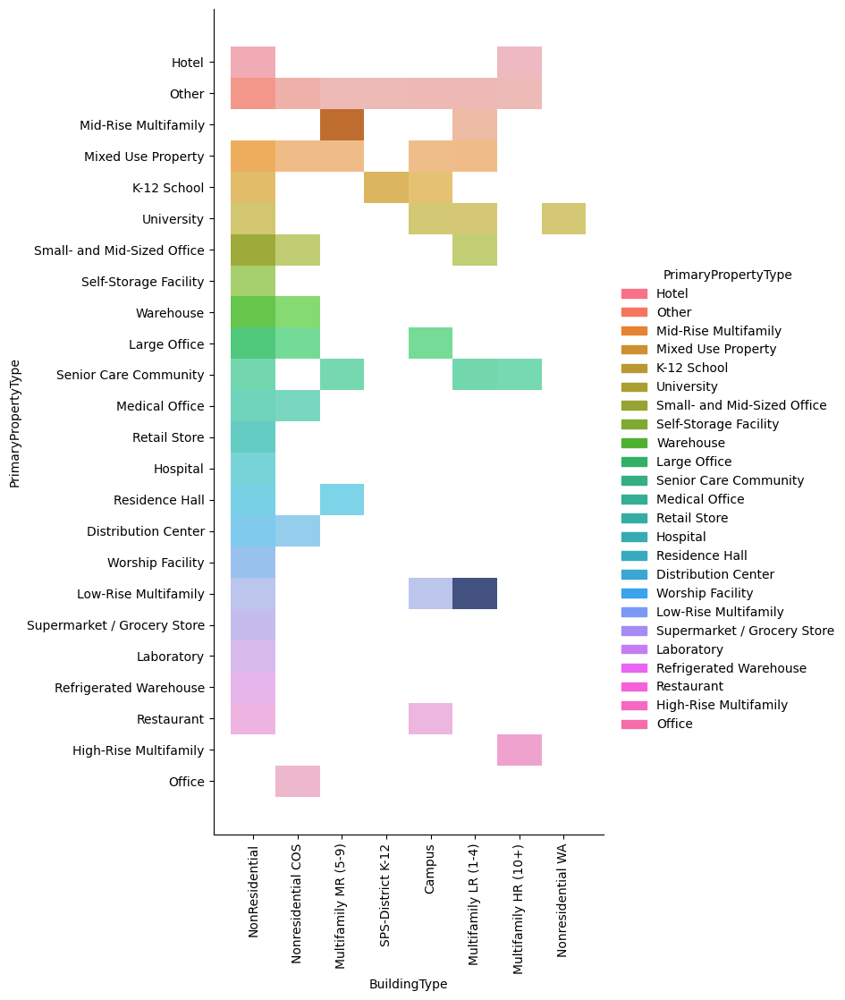

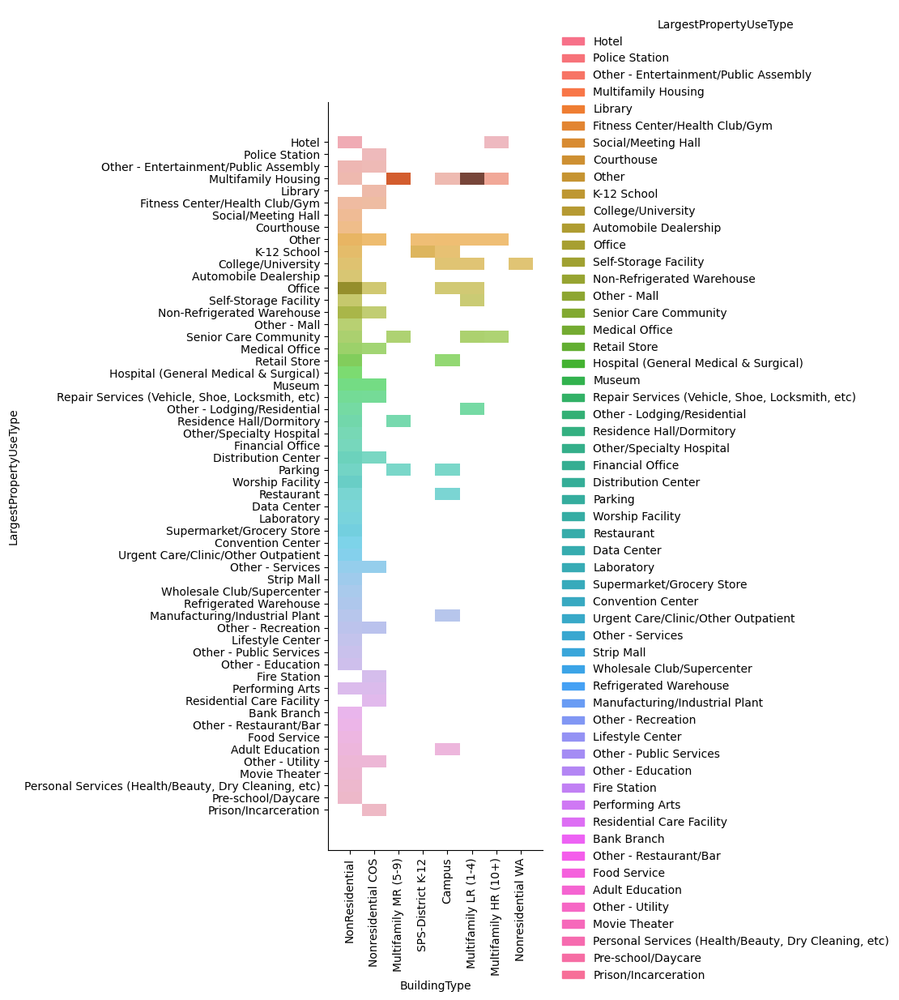

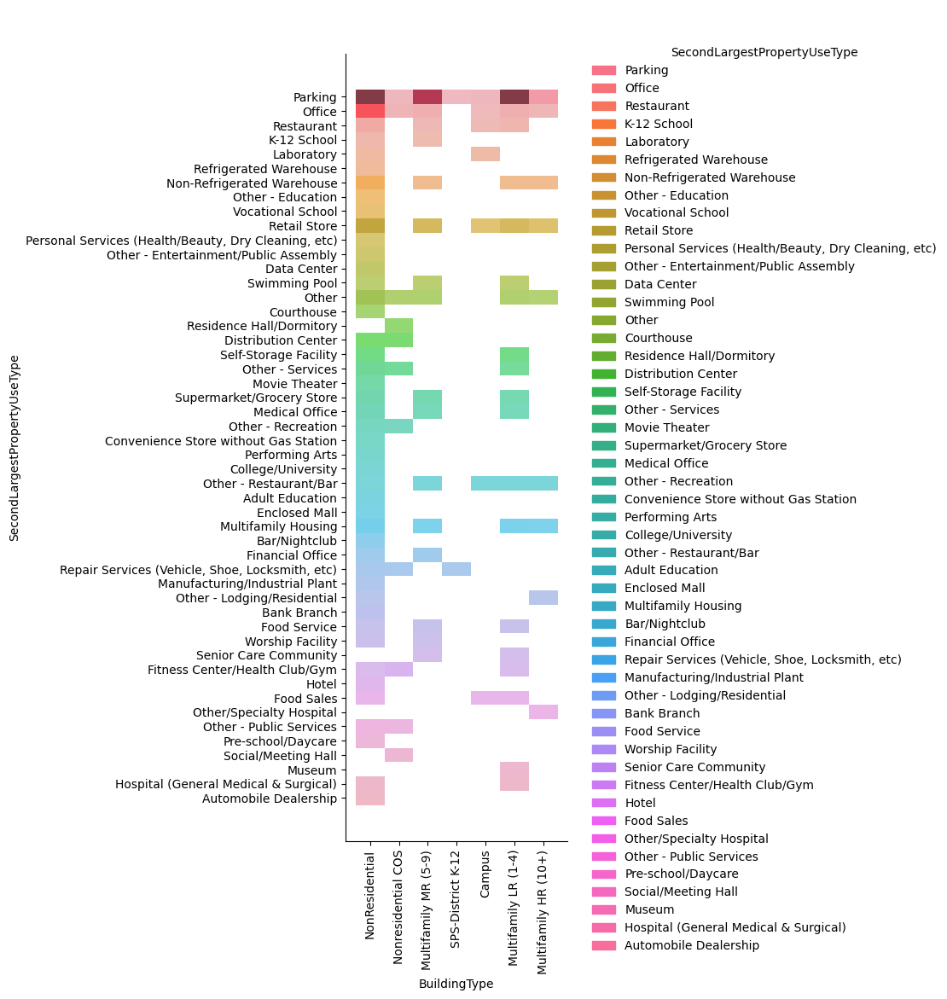

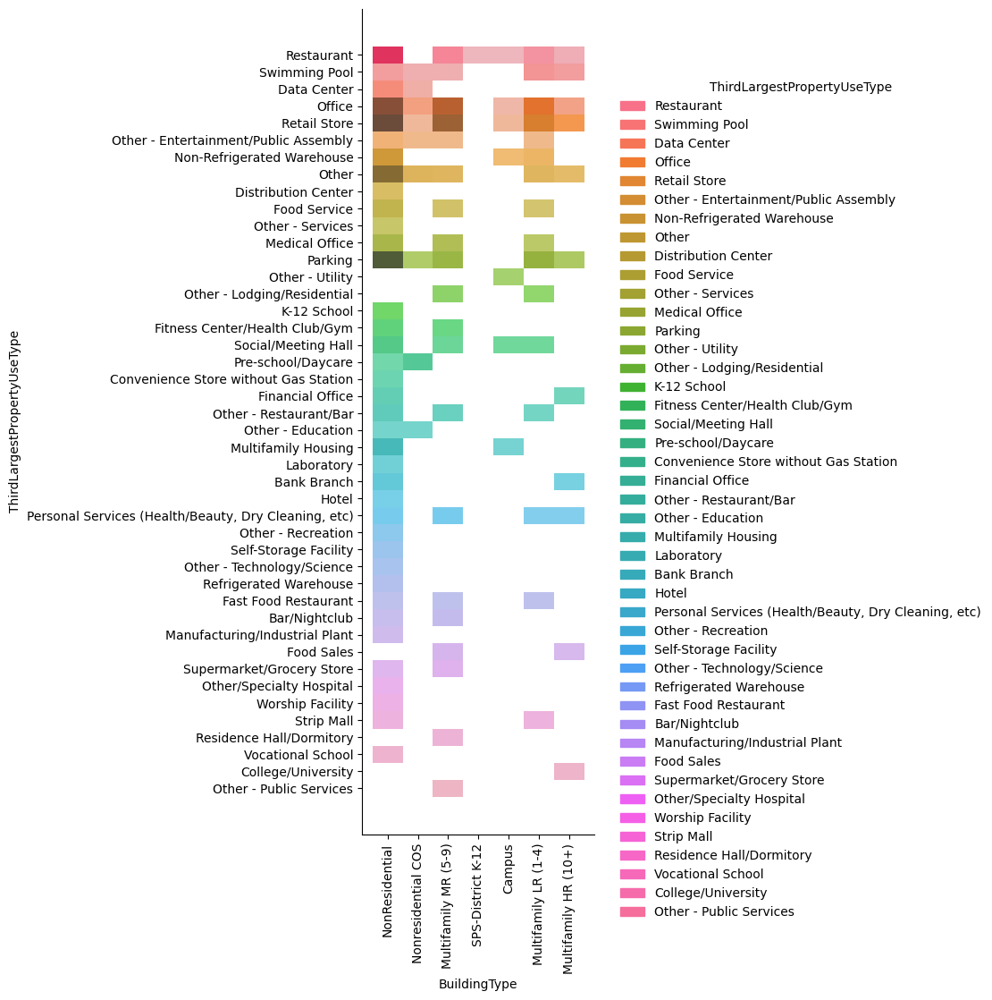

In [ ]:
#pour BuildingType
listing_type_use=['PrimaryPropertyType',
                  'LargestPropertyUseType',
                  'SecondLargestPropertyUseType',
                  'ThirdLargestPropertyUseType'#,
                  #'ListOfAllPropertyUseTypes'
                  ]

for type_use in listing_type_use:    
    g = sns.pairplot(building_consumption,x_vars= 'BuildingType',y_vars=type_use,hue=type_use, height=10, aspect=0.7, kind='hist')
    for ax in g.axes.flatten():
        ax.set_xticklabels(ax.get_xticklabels(), rotation=90)



C:\Users\Myself\AppData\Local\Temp\ipykernel_14616\4143303522.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
C:\Users\Myself\AppData\Local\Temp\ipykernel_14616\4143303522.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
C:\Users\Myself\AppData\Local\Temp\ipykernel_14616\4143303522.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


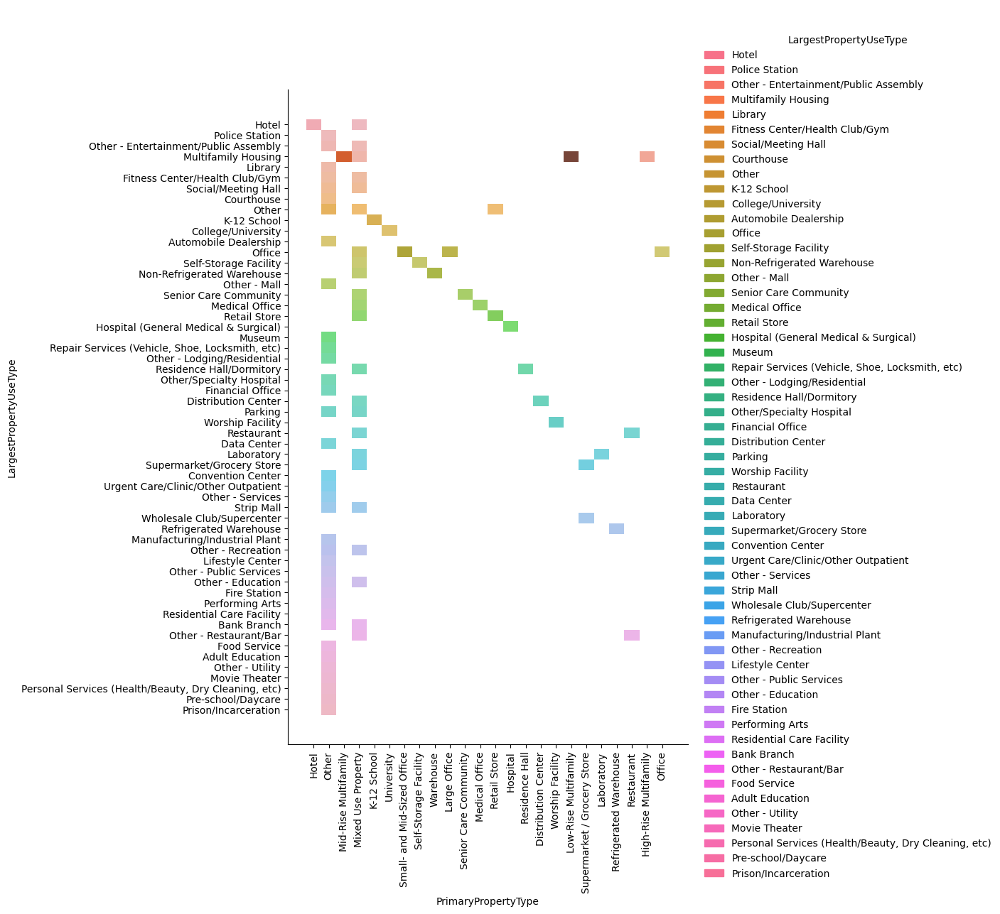

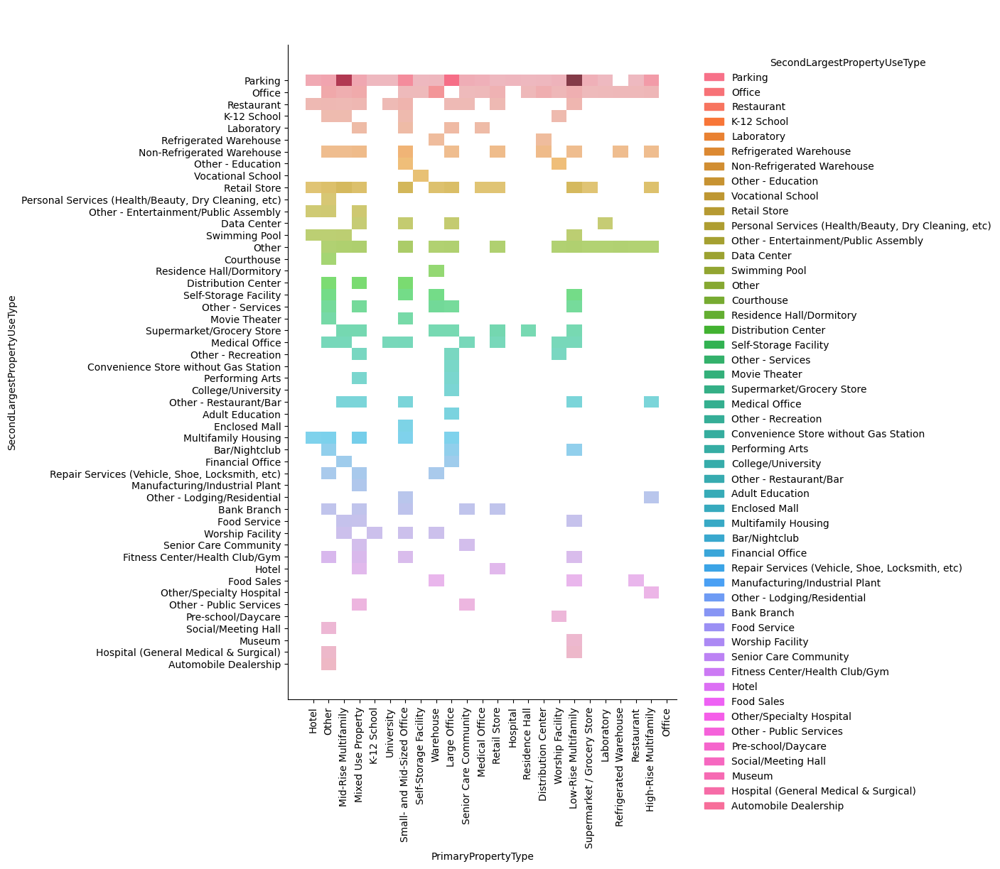

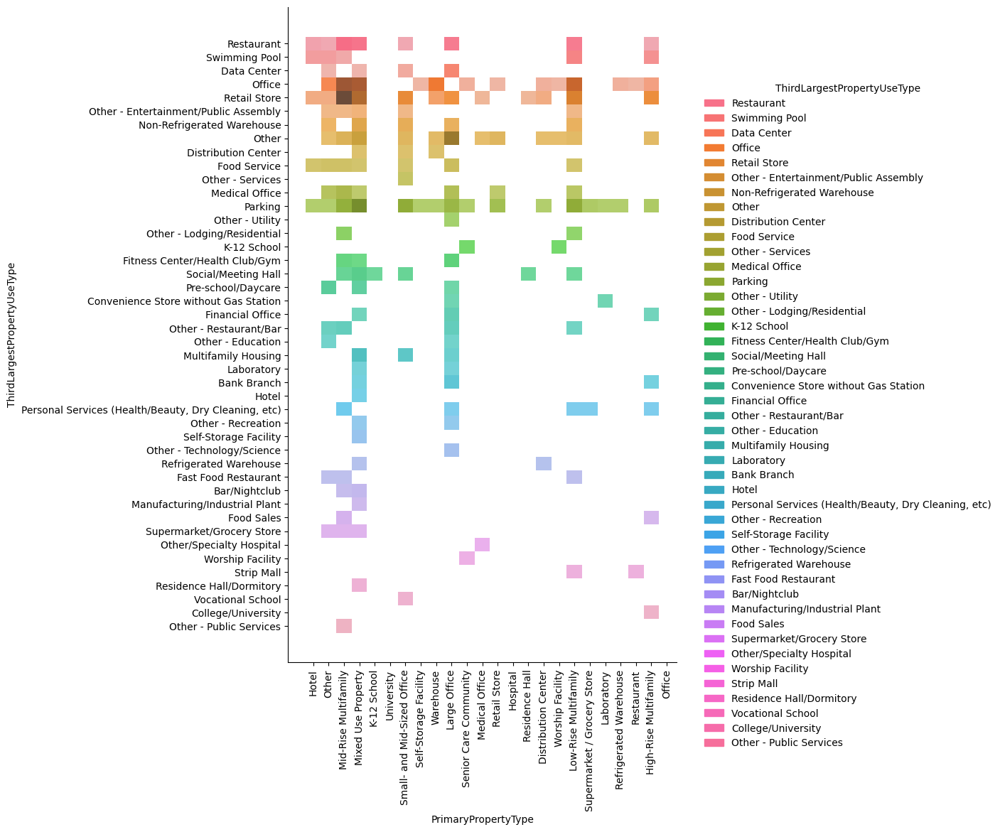

In [85]:
#pour PrimaryPropertyType
listing_type_use=['LargestPropertyUseType',
                  'SecondLargestPropertyUseType',
                  'ThirdLargestPropertyUseType'
                ]

for type_use in listing_type_use:    
    g = sns.pairplot(building_consumption,x_vars= 'PrimaryPropertyType',y_vars=type_use,hue=type_use, height=10, aspect=1, kind='hist')
    for ax in g.axes.flatten():
        ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

h:\python_project\Projet3\.venv\Lib\site-packages\seaborn\axisgrid.py:123: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)
C:\Users\Myself\AppData\Local\Temp\ipykernel_7884\673872961.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


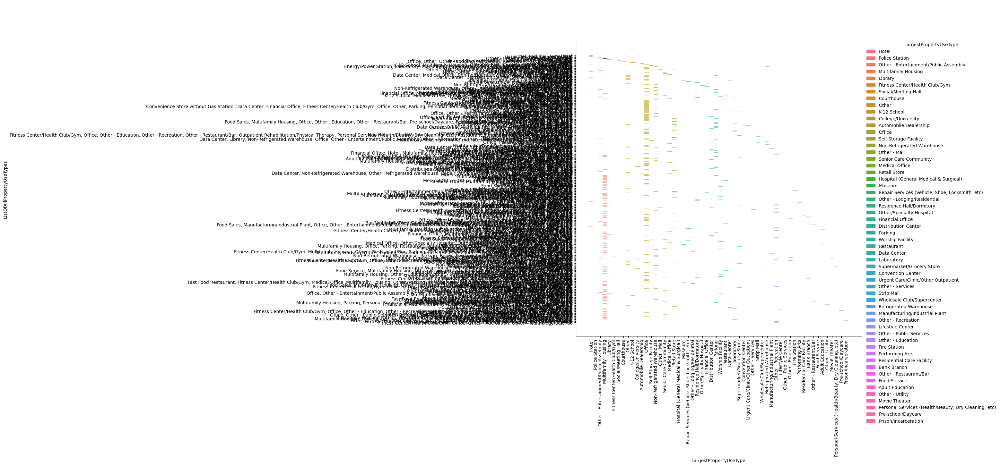

In [4]:
my_value='ListOfAllPropertyUseTypes'
g = sns.pairplot(building_consumption,x_vars= 'LargestPropertyUseType',y_vars='ListOfAllPropertyUseTypes',hue='LargestPropertyUseType', height=10, aspect=1, kind='hist')
for ax in g.axes.flatten():
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
plt.show()


### Puis on réessaye le Filtrage des doublons du 2.1.1 avec sur le building type

In [ ]:
critere='LargestPropertyUseType' #'BuildingType', 'PrimaryPropertyType','LargestPropertyUseType'
bc_no_housing = building_consumption[(building_consumption[critere].str.contains('Multifamily')==False)]
bc_no_housing

bc_no_housing.value_counts(normalize=True, subset=['PropertyName'])
for PropertyName in enumerate(bc_no_housing['PropertyName'].value_counts().index.tolist()):
    count = bc_no_housing[bc_no_housing['PropertyName']==PropertyName[1]]['PropertyName'].value_counts()[PropertyName[1]]
    
    if(count>1):
        #print('PropertyName :', PropertyName[1],'Counts :',count)
        b1 = bc_no_housing[bc_no_housing['PropertyName']==PropertyName[1]]
        print( 'Counts :',count,b1[['PropertyName','BuildingType','PrimaryPropertyType','LargestPropertyUseType']].to_string())  

Counts : 2          PropertyName          BuildingType    PrimaryPropertyType LargestPropertyUseType
323   Northgate Plaza        NonResidential           Large Office                 Office
1644  Northgate Plaza  Multifamily LR (1-4)  Senior Care Community  Senior Care Community
Counts : 2         PropertyName    BuildingType          PrimaryPropertyType      LargestPropertyUseType
1158  Canal Building  NonResidential                    Warehouse  Non-Refrigerated Warehouse
1566  Canal Building  NonResidential  Small- and Mid-Sized Office                      Office
Counts : 2      PropertyName    BuildingType PrimaryPropertyType      LargestPropertyUseType
162    South Park          Campus        Large Office                      Office
1462   South Park  NonResidential           Warehouse  Non-Refrigerated Warehouse
Counts : 2           PropertyName    BuildingType          PrimaryPropertyType      LargestPropertyUseType
1338  Bayview Building  NonResidential  Small- and Mid-Sized O

#### **Constat** 
On retrouve moins de doublons car toute la partie housing "n'est plus visible"
En changeant la valeur de "critere" par 'BuildingType'(8 valeurs),'PrimaryPropertyType'(12),'LargestPropertyUseType'(10) le résultat varie

### 2.4 Visu Pie Chart des Neighborhoods

Neighborhoods : ['DOWNTOWN' 'SOUTHEAST' 'NORTHEAST' 'EAST' 'Central' 'NORTH'
 'MAGNOLIA / QUEEN ANNE' 'LAKE UNION' 'GREATER DUWAMISH' 'BALLARD'
 'NORTHWEST' 'CENTRAL' 'SOUTHWEST' 'DELRIDGE' 'Ballard' 'North' 'Delridge'
 'Northwest' 'DELRIDGE NEIGHBORHOODS']
Sizes : [573 453 423 375 280 251 210 166 145 126 107  95  80  42  27  11   7   4
   1]


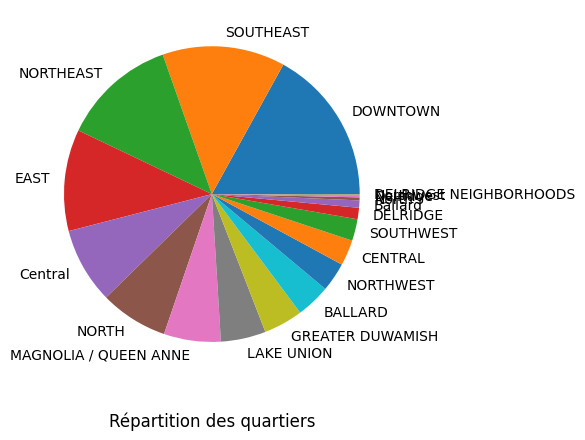

In [4]:
neighborhoods = pd.unique(building_consumption['Neighborhood'].to_numpy().flatten())
print('Neighborhoods :',neighborhoods)  
sizes = building_consumption['Neighborhood'].value_counts().to_numpy().flatten()
print('Sizes :',sizes)
fig, ax = plt.subplots()
ax.pie(sizes, labels=neighborhoods)
# Titre en bas
plt.title("Répartition des quartiers", y=-0.15)
plt.show()

### 3 Recherche des valeurs inutilisables

#### 3.1 GFA

Graph par building Type

*************PrimaryPropertyGFA :  [ 88434  88502 759392 ...  13157  14101  18258]
Mean :  86832.01125592417
Max :  9320156


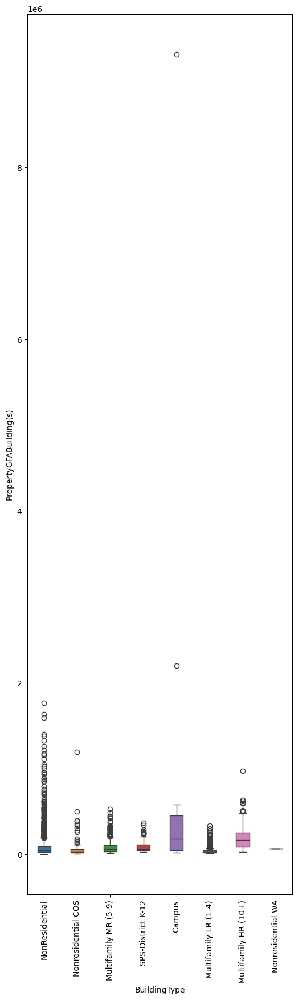

In [ ]:
my_value1 = 'PropertyGFABuilding(s)'
my_value2 = 'BuildingType'

# for column in building_consumption:
#     my_value = column
#     plot=sns.boxplot(data=building_consumption,y=building_consumption[column],hue=my_value)
#     plt.setp(plot.get_xticklabels(), rotation=90)
#     plt.show()

print('*************PropertyGFABuilding : ',pd.unique(building_consumption[my_value1].to_numpy().flatten()))
print('Mean : ',building_consumption[my_value1].mean())
print('Max : ',building_consumption[my_value1].max())

#surface max  9320156 sqft équivalente 121,270 Terrain de football
#https://www.convertir-unites.info/convertisseur-d-unites.php

fig = plt.figure(figsize=(6,20))


for my_value in [my_value2]:
    plot=sns.boxplot(data=building_consumption,x=my_value,y=my_value1,hue=my_value,gap=0.5)
    plt.setp(plot.get_xticklabels(), rotation=90)
    plt.show()

Graph par LargestPropertyUseType

*************LargestPropertyUseTypeGFA :  [ 88434.  83880. 756493. ...   7583.   6601.   8271.]
Mean :  79177.63855780692
Max :  9320156.0


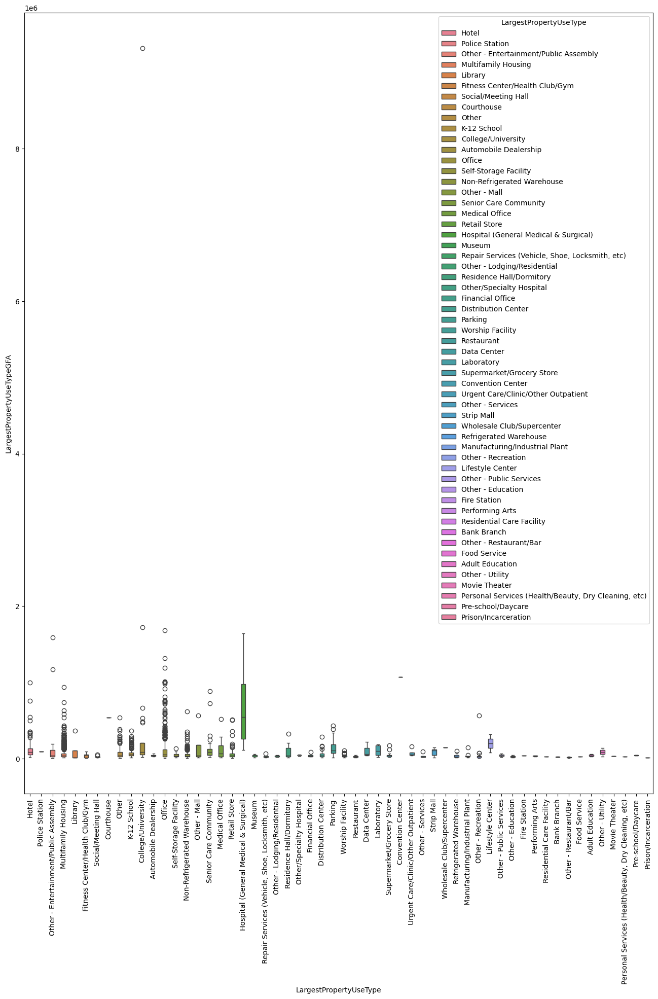

In [9]:
my_value1 = 'LargestPropertyUseTypeGFA'
my_value2 = 'LargestPropertyUseType'

# for column in building_consumption:
#     my_value = column
#     plot=sns.boxplot(data=building_consumption,y=building_consumption[column],hue=my_value)
#     plt.setp(plot.get_xticklabels(), rotation=90)
#     plt.show()

print('*************LargestPropertyUseTypeGFA : ',pd.unique(building_consumption[my_value1].to_numpy().flatten()))
print('Mean : ',building_consumption[my_value1].mean())
print('Max : ',building_consumption[my_value1].max())

fig = plt.figure(figsize=(16,20))


for my_value in [my_value2]:
    plot=sns.boxplot(data=building_consumption,x=my_value,y=my_value1,hue=my_value,gap=0.5)
    plt.setp(plot.get_xticklabels(), rotation=90)
    plt.show()

#graph surface en dessous

#### 3.2 Consommation

Choix du SiteEnergyUse(kBtu)

27.  YearsENERGYSTARCertified         119 non-null    object 
28.  ENERGYSTARScore                  2533 non-null   float64
29.  SiteEUI(kBtu/sf)                 3369 non-null   float64
30.  SiteEUIWN(kBtu/sf)               3370 non-null   float64
31.  SourceEUI(kBtu/sf)               3367 non-null   float64
32.  SourceEUIWN(kBtu/sf)             3367 non-null   float64
33.  **SiteEnergyUse(kBtu)**          3371 non-null   float64
34.  SiteEnergyUseWN(kBtu)            3370 non-null   float64
35.  ==SteamUse(kBtu)==               3367 non-null   float64
36.  Electricity(kWh)                 3367 non-null   float64
37.  ==Electricity(kBtu)==            3367 non-null   float64
38.  NaturalGas(therms)               3367 non-null   float64
39.  ==NaturalGas(kBtu)==             3367 non-null   float64
44. TotalGHGEmissions 3367 non-null float64
45. GHGEmissionsIntensity 3367 non-null float64

Ceux annotés 
- WN sont influencés par des données de temps non présente et non réutilisable.
- EUI est une propriété lié à la consommation énergétique du site divisée par sa surface brute au sol
- /sf est une normalisation sur 30 ans



*************PropertyGFABuilding :  [ 7226362.5     8387933.     72587024.     ...  5765898.       719471.1875
  1152896.25  ]
Mean :  5403667.294533343
Max :  873923712.0


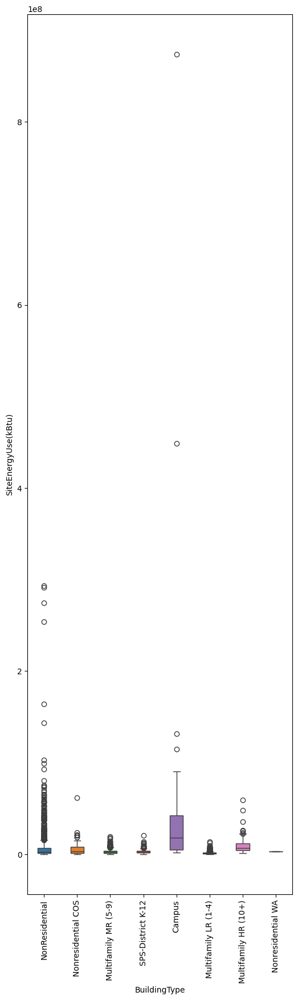

In [ ]:
my_value1 = 'SiteEnergyUse(kBtu)'
my_value2 = 'BuildingType'

# for column in building_consumption:
#     my_value = column
#     plot=sns.boxplot(data=building_consumption,y=building_consumption[column],hue=my_value)
#     plt.setp(plot.get_xticklabels(), rotation=90)
#     plt.show()

print('*************PropertyGFABuilding : ',pd.unique(building_consumption[my_value1].to_numpy().flatten()))
print('Mean : ',building_consumption[my_value1].mean())
print('Max : ',building_consumption[my_value1].max())
#la surface d'origine étant abérente, la donnée énergetique est abérente

fig = plt.figure(figsize=(6,20))


for my_value in [my_value2]:
    plot=sns.boxplot(data=building_consumption,x=my_value,y=my_value1,hue=my_value,gap=0.5)
    plt.setp(plot.get_xticklabels(), rotation=90)
    plt.show()

#graph en dessous

#### 3.3 Recherche des outliers dans le tableau :

In [ ]:
outlier_min = building_consumption[(building_consumption['Outlier']=='Low outlier')]
outlier_min #23

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
384,539,2016,NonResidential,Retail Store,University Center,4501 Roosevelt Way NE,Seattle,WA,98105.0,5335200380,...,93482.601560,318963.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,2.22,0.03
448,608,2016,NonResidential,Large Office,411 1ST AVE S (ID608),411 1ST AVE S,Seattle,WA,98104.0,5247800200,...,471503.000000,1608768.0,3430.500488,343050.0,False,NaN,Non-Compliant,Low outlier,29.43,0.19
720,19708,2016,Multifamily HR (10+),High-Rise Multifamily,Bay Vista,2821 2nd Ave,Seattle,WA,98121.0,0586400000,...,626561.625000,2137828.0,2700.760010,270076.0,False,NaN,Non-Compliant,Low outlier,29.25,0.17
834,19934,2016,Multifamily LR (1-4),Low-Rise Multifamily,Belmont Lofts,231 Belmont Ave E,Seattle,WA,98102.0,0704600000,...,75020.898440,255971.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,1.78,0.06
839,19967,2016,SPS-District K-12,K-12 School,Queen Anne Gym,1431 2nd Ave N,Seattle,WA,98109.0,0811000005,...,72282.398440,246628.0,1848.439575,184844.0,True,NaN,Error - Correct Default Data,Low outlier,11.54,0.32
962,20367,2016,Multifamily LR (1-4),Low-Rise Multifamily,City Lights on Harbor,2349 Harbor Ave. SW,Seattle,WA,98126.0,1595200000,...,205885.500000,702481.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,4.90,0.07
1045,20617,2016,NonResidential,Retail Store,Seattle Habitat Store,21 S Nevada St,Seattle,WA,98134.0,1824049074,...,14362.500000,49005.0,964.640015,96464.0,True,NaN,Error - Correct Default Data,Low outlier,5.46,0.14
1229,21315,2016,NonResidential,Small- and Mid-Sized Office,1518 Fifith Ave,1520 Fifth Ave,Seattle,WA,98101.0,1975700135,...,7064.899902,24105.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,0.17,0.00
1295,21474,2016,NonResidential,Other,The Lusty Lady,1315 1st Ave,Seattle,WA,98101.0,1976200060,...,12981.700200,44294.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,0.31,0.01
1341,21562,2016,Multifamily LR (1-4),Low-Rise Multifamily,Diplomat Condominiums,4444 44th Avenue SW,Seattle,WA,98116.0,2041200000,...,56124.800780,191498.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,1.34,0.04


In [ ]:
outlier_max = building_consumption[( building_consumption['Outlier']=='High outlier')]
outlier_max #9

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
226,350,2016,NonResidential,Large Office,Second And Spring Building,1100 Second Avenue,Seattle,WA,98101.0,0942000045,...,1.166315e+07,39794668.0,16048.309570,1604831.0,False,NaN,Non-Compliant,High outlier,362.66,2.10
517,704,2016,NonResidential,Large Office,401 Elliott Ave West,401 Elliot Ave West,Seattle,WA,98119.0,7666202110,...,7.953454e+06,27137187.0,0.000000,0.0,False,NaN,Non-Compliant,High outlier,189.18,1.46
1707,23174,2016,Multifamily LR (1-4),Mid-Rise Multifamily,Taylor Anne Condominium,1730 Taylor Ave N,Seattle,WA,98109.0,8567250000,...,1.961078e+06,6691197.0,1432.329956,143233.0,False,NaN,Non-Compliant,High outlier,54.25,1.77
2763,26852,2016,Multifamily LR (1-4),Low-Rise Multifamily,Atlas Building,420 Maynard Avenue South,Seattle,WA,98104.0,5247802315,...,5.148407e+05,1756636.0,51247.687500,5124769.0,False,NaN,Non-Compliant,High outlier,284.42,6.11
2863,27245,2016,Multifamily LR (1-4),Low-Rise Multifamily,St. Johns Apartments,725 E. Pike Street,Seattle,WA,98122.0,7502500061,...,2.937813e+05,1002382.0,16793.890630,1679389.0,False,NaN,Non-Compliant,High outlier,96.18,3.90
2922,27526,2016,Multifamily LR (1-4),Low-Rise Multifamily,Vali Hai,800 1st Ave N.,Seattle,WA,98112.0,5457300300,...,5.843347e+05,1993750.0,25253.650390,2525365.0,False,NaN,Non-Compliant,High outlier,148.02,3.41
3082,28735,2016,Multifamily LR (1-4),Low-Rise Multifamily,Building 4,400 NE Thornton Place,Seattle,WA,98125.0,8632880000,...,1.161543e+06,3963184.0,94960.359380,9496036.0,False,NaN,Non-Compliant,High outlier,531.96,11.38
3092,29390,2016,Multifamily MR (5-9),Mid-Rise Multifamily,Commodore Duchess Apartments,4005 15th Ave NE,Seattle,WA,98105.0,1142002395,...,4.597700e+05,1568735.0,696.960022,69696.0,False,NaN,Non-Compliant,High outlier,686.53,7.01
3265,49943,2016,Multifamily LR (1-4),Low-Rise Multifamily,Stewart House,80 Stewart Street,Seattle,WA,98101.0,8008550000,...,1.054889e+06,3599281.0,10035.120120,1003512.0,False,NaN,Non-Compliant,High outlier,78.39,1.60


#### 3.2 trie selon la validité "compliance"

In [53]:
print(f'*************ComplianceStatus : ',pd.unique(building_consumption['ComplianceStatus'].to_numpy().flatten()))

*************ComplianceStatus :  ['Compliant' 'Error - Correct Default Data' 'Missing Data' 'Non-Compliant']


Sizes : [3211  113   37   15]


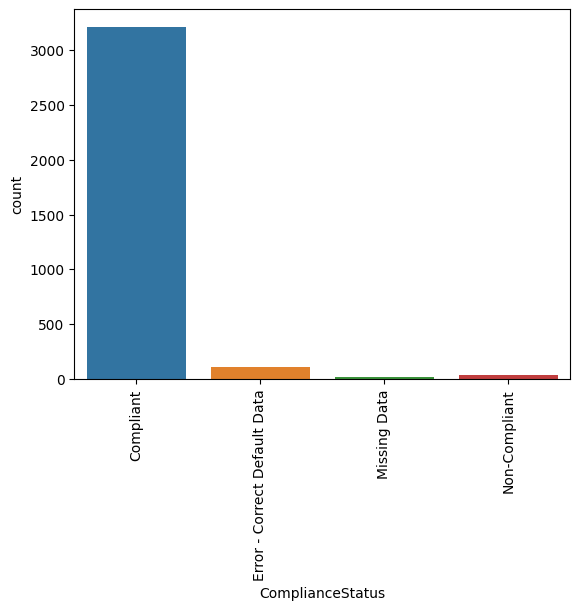

In [56]:
my_value = 'ComplianceStatus'

sizes = building_consumption[my_value].value_counts().to_numpy().flatten()
print('Sizes :',sizes)
plot=sns.countplot(x=my_value,data=building_consumption,hue=my_value)
plt.setp(plot.get_xticklabels(), rotation=90)
plt.show()

### 1er nettoyage
- Par 'Multyfamily Housing'
- Par valeur 'Non-Compliant'
- Par 'Outlier' données

In [5]:


critere='LargestPropertyUseType'
print("--------------------------")
print("total : ",building_consumption[critere].count())
print("--------------------------")
#LargestPropertyUseType sans le 'MutltiFamily Housing'
bc_no_housing = building_consumption[(building_consumption['LargestPropertyUseType'].str.contains('Multifamily')==False)]
print("Sans les Logements : ",bc_no_housing[critere].count())

#retrait des non qualifiés
bc_no_housing = bc_no_housing[(bc_no_housing['ComplianceStatus'].str.contains('Non-Compliant')==False)]
print("Sans les non qualifiés : ",bc_no_housing[critere].count())

print("--------------------------")
print("Nb de outlier : ",bc_no_housing['Outlier'].count())
print("Nb valeurs extremes : ",bc_no_housing[(bc_no_housing['Outlier']=='High outlier')]['Outlier'].count())
print("--------------------------")
#retrait des high outlier
# bc_no_housing = bc_no_housing[(bc_no_housing['Outlier'].str.contains('High outlier')==False)]
# print("Sans les valeurs extremes : ",bc_no_housing[critere].count())

bc_no_housing.info()

--------------------------
total :  3356
--------------------------
Sans les Logements :  1689
Sans les non qualifiés :  1674
--------------------------
Nb de outlier :  2
Nb valeurs extremes :  0
--------------------------
<class 'pandas.core.frame.DataFrame'>
Index: 1674 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    1674 non-null   int64  
 1   DataYear                         1674 non-null   int64  
 2   BuildingType                     1674 non-null   object 
 3   PrimaryPropertyType              1674 non-null   object 
 4   PropertyName                     1674 non-null   object 
 5   Address                          1674 non-null   object 
 6   City                             1674 non-null   object 
 7   State                            1674 non-null   object 
 8   ZipCode                          1658 non-null   

#### Affichage des IQR de la surface

*************LargestPropertyUseTypeGFA :  [ 88434.  83880. 756493. ...   7583.   6601.   8271.]
Mean :  99304.63978494624
Max :  9320156.0


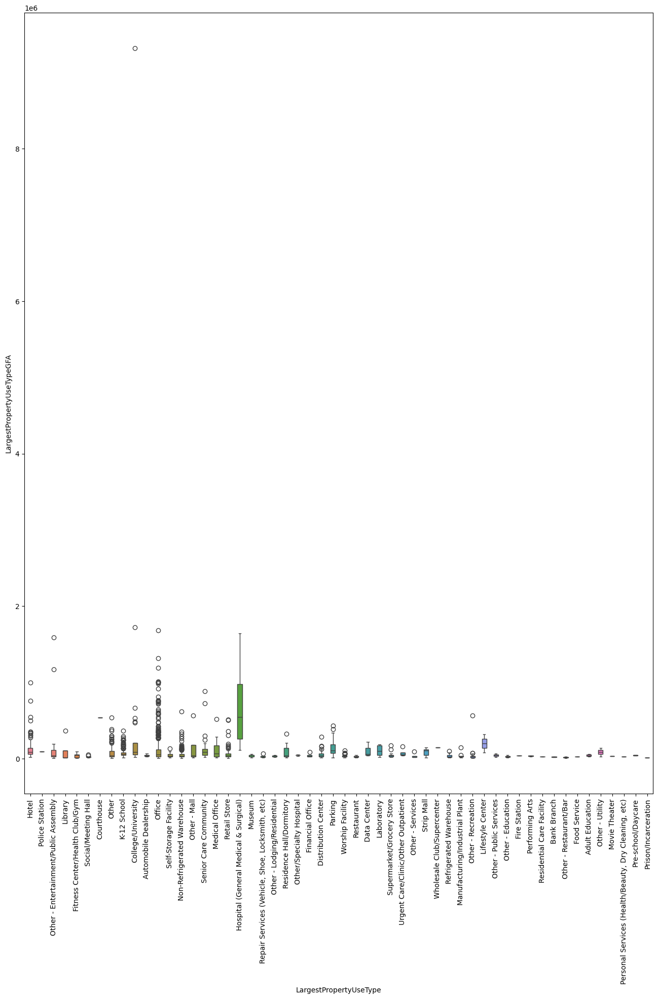

In [6]:
my_value1 = 'LargestPropertyUseTypeGFA'
my_value2 = 'LargestPropertyUseType'

# for column in building_consumption:
#     my_value = column
#     plot=sns.boxplot(data=building_consumption,y=building_consumption[column],hue=my_value)
#     plt.setp(plot.get_xticklabels(), rotation=90)
#     plt.show()

print('*************LargestPropertyUseTypeGFA : ',pd.unique(bc_no_housing[my_value1].to_numpy().flatten()))
print('Mean : ',bc_no_housing[my_value1].mean())
print('Max : ',bc_no_housing[my_value1].max())

fig = plt.figure(figsize=(16,20))


for my_value in [my_value2]:
    plot=sns.boxplot(data=bc_no_housing,x=my_value,y=my_value1,hue=my_value,gap=0.5)
    plt.setp(plot.get_xticklabels(), rotation=90)
    plt.show()

# graph en dessous

### Conclusion
Données retenues
- 'LargestPropertyUseTypeGFA' et 'LargestPropertyUseType' sans le 'MutltiFamily Housing' 
    - car on a une correspondance entre surface et type
    - donnée la plus propre pour le tri des non résidentiels
- 'SiteEnergyUse(kBtu)'
- YearBuilt
- Neighborhood
- Cartographie: OSEBuildingID, PropertyName, Latitude et Longitude


In [8]:
df = bc_no_housing[['OSEBuildingID','PropertyName',
                   'Latitude','Longitude','Neighborhood',
                   'YearBuilt','LargestPropertyUseType','LargestPropertyUseTypeGFA',
                   'SiteEnergyUse(kBtu)','SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)'
                   ]]
df.info() #1674 valeurs

<class 'pandas.core.frame.DataFrame'>
Index: 1674 entries, 0 to 3375
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   OSEBuildingID              1674 non-null   int64  
 1   PropertyName               1674 non-null   object 
 2   Latitude                   1674 non-null   float64
 3   Longitude                  1674 non-null   float64
 4   Neighborhood               1674 non-null   object 
 5   YearBuilt                  1674 non-null   int64  
 6   LargestPropertyUseType     1674 non-null   object 
 7   LargestPropertyUseTypeGFA  1674 non-null   float64
 8   SiteEnergyUse(kBtu)        1674 non-null   float64
 9   SteamUse(kBtu)             1674 non-null   float64
 10  Electricity(kBtu)          1674 non-null   float64
 11  NaturalGas(kBtu)           1674 non-null   float64
dtypes: float64(7), int64(2), object(3)
memory usage: 170.0+ KB


### Nettoyage par écart interquartile
Q3+1,5*IQR ou Q1–1,5*IQR

#### Vérification des valeurs extrêmes

In [122]:
def checker(my_value):
    print('----------------------------------------------------',my_value)
    df1=df.sort_values(by=[my_value], ascending=False)
    print(df1[my_value].to_string())

checker('Longitude')
checker('Latitude')
checker('LargestPropertyUseTypeGFA')
checker('SiteEnergyUse(kBtu)')

---------------------------------------------------- Longitude
3084   -122.220966
109    -122.258640
3340   -122.261800
3131   -122.262230
3130   -122.262350
1119   -122.262770
913    -122.262930
3132   -122.262990
1981   -122.263060
3168   -122.263300
106    -122.264560
2584   -122.265560
132    -122.265860
904    -122.266700
447    -122.268250
22     -122.268530
1893   -122.269220
2691   -122.269350
3201   -122.270540
3254   -122.270740
1356   -122.270920
687    -122.270970
3126   -122.272010
3097   -122.273240
900    -122.273800
1355   -122.274660
2103   -122.275330
87     -122.275960
1757   -122.276160
2524   -122.276520
141    -122.276910
2518   -122.277060
2105   -122.277390
2802   -122.277960
3369   -122.278130
3165   -122.278170
1123   -122.278750
681    -122.279460
1974   -122.279780
2535   -122.280260
3073   -122.280610
2522   -122.280670
680    -122.281000
683    -122.281000
2080   -122.281430
124    -122.281460
682    -122.281920
129    -122.281980
684    -122.282450
2355  

Résumé sur Tableau

|     | LargestPropertyUseTypeGFA                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               | SiteEnergyUse(kBtu)                                                                                                                                                                                                                                                                                                                                                                          |
| --- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Max | 3274    9320156.0<br>1494    1719643.0<br>559     1680937.0<br>618     1639334.0<br>155     1585960.0<br>170     1350182.0<br>292     1314475.0<br>233     1191115.0<br>158     1172127.0<br>221     1011135.0<br>3264    1010135.0<br>273     1002403.0<br>477     1000730.0                                                                                                                                                                                                                                                                                                                                                                                           | 3274    8.739237e+08<br>35      4.483853e+08<br>170     2.930908e+08<br>618     2.916144e+08<br>558     2.746822e+08<br>124     2.538325e+08                                                                                                                                                                                                                                                 |
| Min | 2720      10800.0<br>1352      10751.0<br>911       10495.0<br>2248      10471.0<br>2683      10420.0<br>1473      10388.0<br>1425      10292.0<br>2446      10228.0<br>1568      10200.0<br>1162      10155.0<br>1266      10109.0<br>3360       9900.0<br>2444       9750.0<br>1599       9500.0<br>2182       9000.0<br>830        8969.0<br>1900       8711.0<br>3364       8680.0<br>3375       8271.0<br>2019       8223.0<br>3368       8108.0<br>1288       8061.0<br>985        7758.0<br>3373       7583.0<br>2562       7501.0<br>912        7387.0<br>1134       7245.0<br>986        6900.0<br>3374       6601.0<br>1309       6455.0<br>2904       5656.0 | 1361    0.000000e+00<br>133     0.000000e+00<br>1894    0.000000e+00<br>139     0.000000e+00<br>152     0.000000e+00<br>62      0.000000e+00<br>85      0.000000e+00<br>95      0.000000e+00<br>3166    0.000000e+00<br>81      0.000000e+00<br>760     0.000000e+00<br>746     0.000000e+00<br>614     0.000000e+00<br>630     0.000000e+00<br>31      0.000000e+00<br>28      0.000000e+00 |

In [9]:
# stepframe=df[[#'Latitude','Longitude'#,
#                 'LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)'
#                    #'SiteEnergyUse(kBtu)','SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)'
#                    ]]

df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']]
df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']][df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']] > 150] *= 10
#print (stepframe)

Q1 = df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']].quantile(0.25)
Q3 = df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']].quantile(0.75)
IQR = Q3 - Q1

df_clean = df[~((df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']] < (Q1 - 1.5 * IQR)) |(df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']] > (Q3 + 1.5 * IQR))).any(axis=1)]

print (df_clean) #1441 rows


      OSEBuildingID                         PropertyName  Latitude  Longitude  \
0                 1                 Mayflower park hotel  47.61220 -122.33799   
1                 2                      Paramount Hotel  47.61317 -122.33393   
3                 5                            HOTEL MAX  47.61412 -122.33664   
4                 8          WARWICK SEATTLE HOTEL (ID8)  47.61375 -122.34047   
5                 9                        West Precinct  47.61623 -122.33657   
...             ...                                  ...       ...        ...   
3371          50222                Horticulture building  47.56722 -122.31154   
3372          50223  International district/Chinatown CC  47.59625 -122.32283   
3373          50224                      Queen Anne Pool  47.63644 -122.35784   
3374          50225          South Park Community Center  47.52832 -122.32431   
3375          50226          Van Asselt Community Center  47.53939 -122.29536   

               Neighborhood

C:\Users\Myself\AppData\Local\Temp\ipykernel_4048\2033244224.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']][df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']] > 150] *= 10
C:\Users\Myself\AppData\Local\Temp\ipykernel_4048\2033244224.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']][df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']] > 150] *= 10


#### Graph des surfaces sans les Outliers 

*************LargestPropertyUseTypeGFA :  [88434. 83880. 61320. ...  7583.  6601.  8271.]
Mean :  51194.33518390007
Max :  194674.0


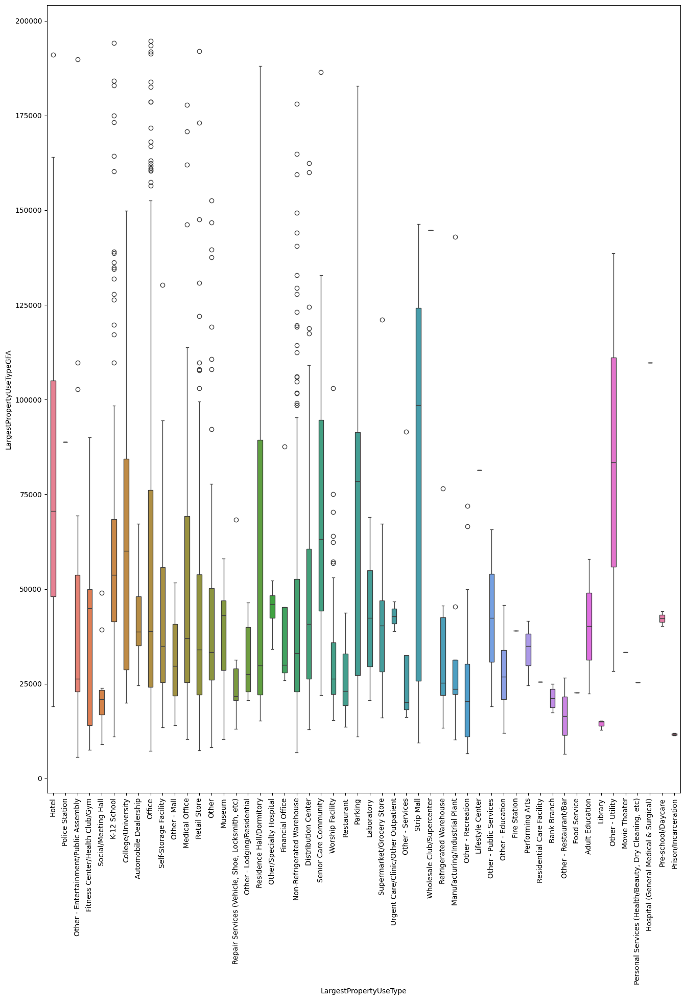

In [ ]:
my_value1 = 'LargestPropertyUseTypeGFA'
my_value2 = 'LargestPropertyUseType'


print('*************LargestPropertyUseTypeGFA : ',pd.unique(df_clean[my_value1].to_numpy().flatten()))
print('Mean : ',df_clean[my_value1].mean())
print('Max : ',df_clean[my_value1].max())

fig = plt.figure(figsize=(16,20))


for my_value in [my_value2]:
    plot=sns.boxplot(data=df_clean,x=my_value,y=my_value1,hue=my_value,gap=0.5)
    plt.setp(plot.get_xticklabels(), rotation=90)
    plt.show()

# graph en dessous

In [125]:
def checker(my_value):
    print('----------------------------------------------------',my_value)
    df1=df_clean.sort_values(by=[my_value], ascending=False)
    print(df1[my_value].to_string())

checker('Longitude')
checker('Latitude')
checker('LargestPropertyUseTypeGFA')
checker('SiteEnergyUse(kBtu)')

---------------------------------------------------- Longitude
3084   -122.220966
109    -122.258640
3340   -122.261800
3131   -122.262230
1119   -122.262770
913    -122.262930
3132   -122.262990
1981   -122.263060
132    -122.265860
904    -122.266700
447    -122.268250
22     -122.268530
1893   -122.269220
2691   -122.269350
3201   -122.270540
3254   -122.270740
1356   -122.270920
687    -122.270970
3126   -122.272010
3097   -122.273240
900    -122.273800
1355   -122.274660
2103   -122.275330
87     -122.275960
1757   -122.276160
141    -122.276910
2518   -122.277060
2105   -122.277390
2802   -122.277960
3369   -122.278130
1123   -122.278750
681    -122.279460
1974   -122.279780
2535   -122.280260
3073   -122.280610
680    -122.281000
683    -122.281000
2080   -122.281430
682    -122.281920
129    -122.281980
684    -122.282450
2355   -122.282670
617    -122.282850
1977   -122.282950
1976   -122.283020
1508   -122.283050
1509   -122.283080
2106   -122.283330
2077   -122.283390
2109  

### 2.5 Carte / Folium

In [ ]:
import folium

#Position [latitude, longitude] sur laquelle est centrée la carte
location = [47.6, -122.3]

#Niveau de zoom initial : 
#3-4 pour un continent, 5-6 pour un pays, 11-12 pour une ville
zoom = 14

#Style de la carte
tiles = 'cartodbpositron'

Carte = folium.Map(location = location,
                   zoom_start = zoom,
                   tiles = tiles)


#Création du marqueur
for row in df_clean[['Latitude','Longitude','PropertyName']].to_numpy():
    marqueur = folium.Marker(location =  (row[0],row[1] ),
                            popup = row[2]
                            )

    #Ajout à la carte
    marqueur.add_to(Carte)

display(Carte)

# Modélisation 

### Import des modules 

In [1]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor


### Feature Engineering

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

---
Rappel :

Données retenues

- 'LargestPropertyUseTypeGFA' et 'LargestPropertyUseType' sans le 'MutltiFamily Housing' 
    - car on a une correspondance entre surface et type
    - donnée la plus propre pour le tri des non résidentiels
- 'SiteEnergyUse(kBtu)' voir choix energie **3.2 Consommation**
    - 'SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)' pour transformation en binaire afin de comparer les types d'energie
- 'YearBuilt'
- 'Neighborhood'
- Cartographie: 'OSEBuildingID', 'PropertyName', 'Latitude' et 'Longitude'

In [8]:
# CODE FEATURE ENGINEERING

#tri précédant
# df = bc_no_housing[['OSEBuildingID','PropertyName',
#                    'Latitude','Longitude','Neighborhood',
#                    'YearBuilt','LargestPropertyUseType','LargestPropertyUseTypeGFA',
#                    'SiteEnergyUse(kBtu)','SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)'
#                    ]]

#data sans outlier/housing family/valeurs nulles
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1441 entries, 0 to 3375
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   OSEBuildingID              1441 non-null   int64  
 1   PropertyName               1441 non-null   object 
 2   Latitude                   1441 non-null   float64
 3   Longitude                  1441 non-null   float64
 4   Neighborhood               1441 non-null   object 
 5   YearBuilt                  1441 non-null   int64  
 6   LargestPropertyUseType     1441 non-null   object 
 7   LargestPropertyUseTypeGFA  1441 non-null   float64
 8   SiteEnergyUse(kBtu)        1441 non-null   float64
 9   SteamUse(kBtu)             1441 non-null   float64
 10  Electricity(kBtu)          1441 non-null   float64
 11  NaturalGas(kBtu)           1441 non-null   float64
dtypes: float64(7), int64(2), object(3)
memory usage: 146.4+ KB


### Préparation des features pour la modélisation

In [5]:

#LargestPropertyUseType sans le 'MutltiFamily Housing'
bc_no_housing = building_consumption[(building_consumption['LargestPropertyUseType'].str.contains('Multifamily')==False)]

#retrait des non qualifiés
bc_no_housing = bc_no_housing[(bc_no_housing['ComplianceStatus'].str.contains('Non-Compliant')==False)]

df = bc_no_housing[['OSEBuildingID','PropertyName',
                   'Latitude','Longitude','Neighborhood',
                   'YearBuilt','LargestPropertyUseType','LargestPropertyUseTypeGFA',
                   'SiteEnergyUse(kBtu)','SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)'
                   ]]

Q1 = df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']].quantile(0.25)
Q3 = df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']].quantile(0.75)
IQR = Q3 - Q1

df_clean = df[~((df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']] < (Q1 - 1.5 * IQR)) |(df[['LargestPropertyUseTypeGFA','SiteEnergyUse(kBtu)']] > (Q3 + 1.5 * IQR))).any(axis=1)]

print (df_clean) #1441 rows

      OSEBuildingID                         PropertyName  Latitude  Longitude  \
0                 1                 Mayflower park hotel  47.61220 -122.33799   
1                 2                      Paramount Hotel  47.61317 -122.33393   
3                 5                            HOTEL MAX  47.61412 -122.33664   
4                 8          WARWICK SEATTLE HOTEL (ID8)  47.61375 -122.34047   
5                 9                        West Precinct  47.61623 -122.33657   
...             ...                                  ...       ...        ...   
3371          50222                Horticulture building  47.56722 -122.31154   
3372          50223  International district/Chinatown CC  47.59625 -122.32283   
3373          50224                      Queen Anne Pool  47.63644 -122.35784   
3374          50225          South Park Community Center  47.52832 -122.32431   
3375          50226          Van Asselt Community Center  47.53939 -122.29536   

               Neighborhood

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

#### View test de relation

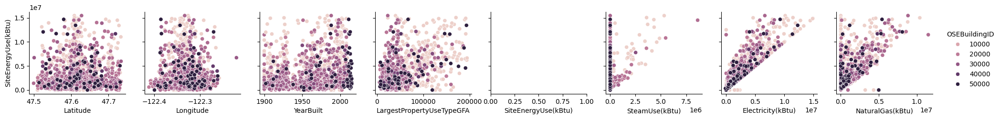

KeyboardInterrupt: 

In [5]:
for colum in df_clean:
    sns.pairplot(
        data=df_clean, hue=colum, y_vars="SiteEnergyUse(kBtu)"
    )
    plt.show()

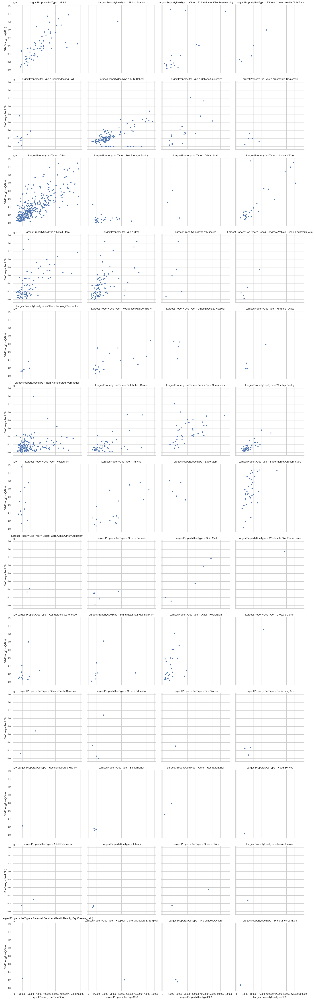

In [ ]:
sns.relplot(
    data=df_clean, x="LargestPropertyUseTypeGFA", y="SiteEnergyUse(kBtu)",
    col="LargestPropertyUseType", col_wrap=4,
    kind="scatter"
)





In [35]:
sns.relplot(
    data=df_clean, x="LargestPropertyUseTypeGFA", y="SiteEnergyUse(kBtu)",
    col="YearBuilt", col_wrap=4,
    kind="scatter"
)

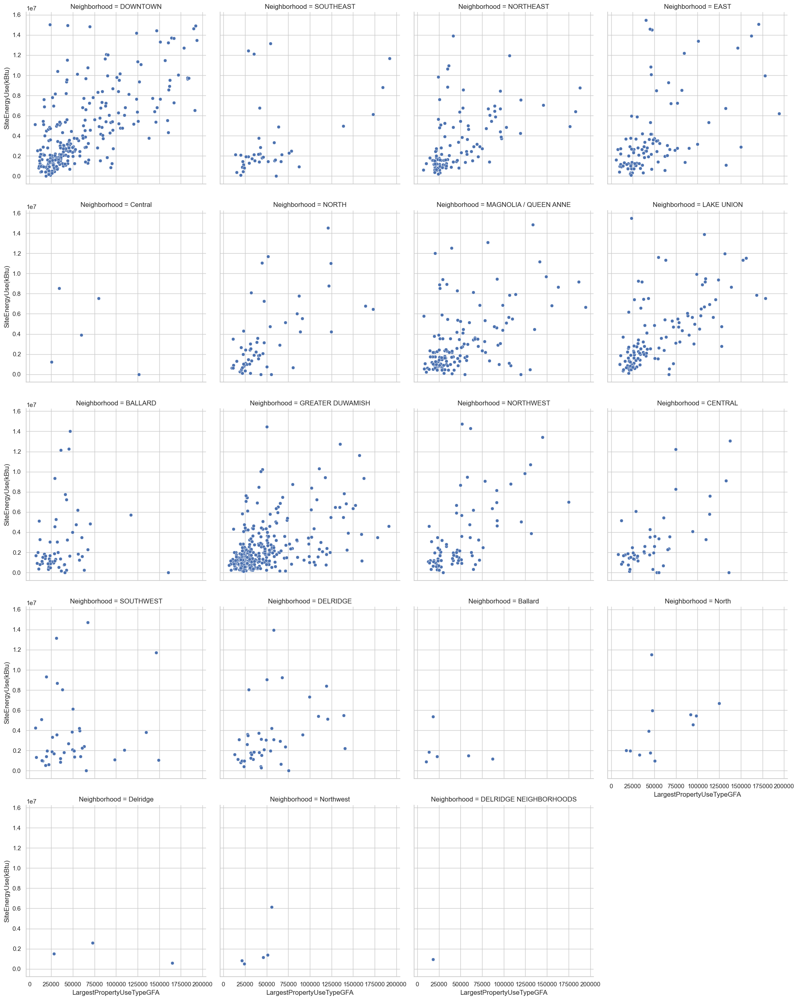

In [36]:
sns.relplot(
    data=df_clean, x="LargestPropertyUseTypeGFA", y="SiteEnergyUse(kBtu)",
    col="Neighborhood", col_wrap=4,
    kind="scatter"
)

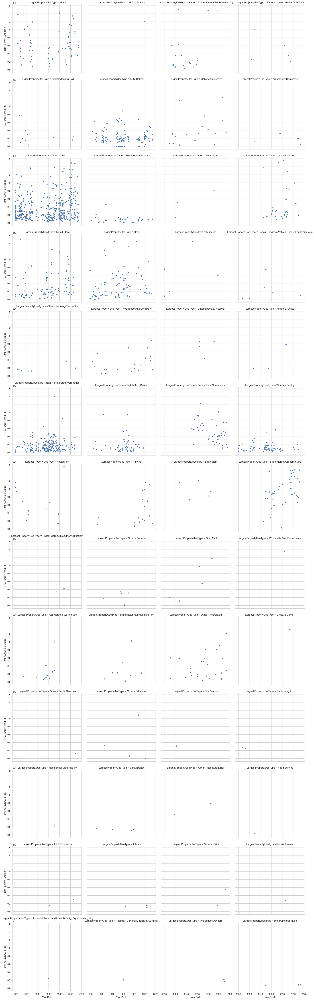

In [37]:
sns.relplot(
    data=df_clean, x="YearBuilt", y="SiteEnergyUse(kBtu)",
    col="LargestPropertyUseType", col_wrap=4,
    kind="scatter"
)

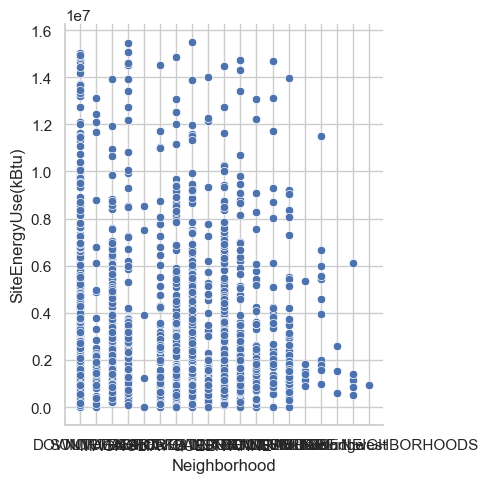

In [39]:
sns.relplot(
    data=df_clean, x="Neighborhood", y="SiteEnergyUse(kBtu)",
    
    kind="scatter"
)

#### Valeur à transformer

---
à convertir en données utilisable :
- 'Neighborhood'
- 'LargestPropertyUseType'
- 'PropertyName'
- 'YearBuilt' en âge

en binaire avec OneHotEncoder :
- 'SteamUse(kBtu)'
- 'Electricity(kBtu)'
- 'NaturalGas(kBtu)'

### Version de recherche/test

Année en âge

In [6]:
#YearBuilt => Age
from datetime import date

current_date = date.today()
current_year = current_date.year
df_clean['Age'] = current_year - df_clean['YearBuilt']
df_clean = df_clean.drop('YearBuilt', axis=1)

C:\Users\Myself\AppData\Local\Temp\ipykernel_3056\923294727.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['Age'] = current_year - df_clean['YearBuilt']


Neighborhood en OneHotEncoder

In [7]:
encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded = encoder.fit_transform(df_clean[['Neighborhood']])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(["Neighborhood"]),
    index=df_clean.index
)

df_neigh = pd.concat([df_clean.drop(columns=["Neighborhood"]), encoded_df], axis=1)
print(df_neigh)

      OSEBuildingID                         PropertyName  Latitude  Longitude  \
0                 1                 Mayflower park hotel  47.61220 -122.33799   
1                 2                      Paramount Hotel  47.61317 -122.33393   
3                 5                            HOTEL MAX  47.61412 -122.33664   
4                 8          WARWICK SEATTLE HOTEL (ID8)  47.61375 -122.34047   
5                 9                        West Precinct  47.61623 -122.33657   
...             ...                                  ...       ...        ...   
3371          50222                Horticulture building  47.56722 -122.31154   
3372          50223  International district/Chinatown CC  47.59625 -122.32283   
3373          50224                      Queen Anne Pool  47.63644 -122.35784   
3374          50225          South Park Community Center  47.52832 -122.32431   
3375          50226          Van Asselt Community Center  47.53939 -122.29536   

     LargestPropertyUseType

LargestPropertyUseType en OneHotEncoder

In [8]:
encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded = encoder.fit_transform(df_neigh[['LargestPropertyUseType']])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(["LargestPropertyUseType"]),
    index=df_neigh.index
)

df_larg = pd.concat([df_neigh.drop(columns=["LargestPropertyUseType"]), encoded_df], axis=1)
print(df_larg)

      OSEBuildingID                         PropertyName  Latitude  Longitude  \
0                 1                 Mayflower park hotel  47.61220 -122.33799   
1                 2                      Paramount Hotel  47.61317 -122.33393   
3                 5                            HOTEL MAX  47.61412 -122.33664   
4                 8          WARWICK SEATTLE HOTEL (ID8)  47.61375 -122.34047   
5                 9                        West Precinct  47.61623 -122.33657   
...             ...                                  ...       ...        ...   
3371          50222                Horticulture building  47.56722 -122.31154   
3372          50223  International district/Chinatown CC  47.59625 -122.32283   
3373          50224                      Queen Anne Pool  47.63644 -122.35784   
3374          50225          South Park Community Center  47.52832 -122.32431   
3375          50226          Van Asselt Community Center  47.53939 -122.29536   

      LargestPropertyUseTyp

Non utilisé

In [9]:
#PropertyName => list int
df_larg=df_larg.drop(columns=["PropertyName"])
df_prop = df_larg

# Initialize and fit LabelEncoder
# le = LabelEncoder()
# df_prop['PropertyName'] = le.fit_transform(df_clean['PropertyName'])

# print(df_prop)
# print("Category Mapping:", le.classes_)

SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)' => Table of boolean

In [10]:
#'SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)' => Table of boolean

df_encoded = df_prop

# Applying one-hot encoding
df_encoded[['SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)']] = df_prop[['SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)']].astype(bool)
df_encoded=df_encoded.drop(columns=["SteamUse(kBtu)"])
# Displaying the encoded DataFrame
#print(df_prop)
print(df_encoded)


      OSEBuildingID  Latitude  Longitude  LargestPropertyUseTypeGFA  \
0                 1  47.61220 -122.33799                    88434.0   
1                 2  47.61317 -122.33393                    83880.0   
3                 5  47.61412 -122.33664                    61320.0   
4                 8  47.61375 -122.34047                   123445.0   
5                 9  47.61623 -122.33657                    88830.0   
...             ...       ...        ...                        ...   
3371          50222  47.56722 -122.31154                    12294.0   
3372          50223  47.59625 -122.32283                    16000.0   
3373          50224  47.63644 -122.35784                     7583.0   
3374          50225  47.52832 -122.32431                     6601.0   
3375          50226  47.53939 -122.29536                     8271.0   

      SiteEnergyUse(kBtu)  Electricity(kBtu)  NaturalGas(kBtu)  Age  \
0            7.226362e+06               True              True   98   
1    

### Corr()

<Axes: >

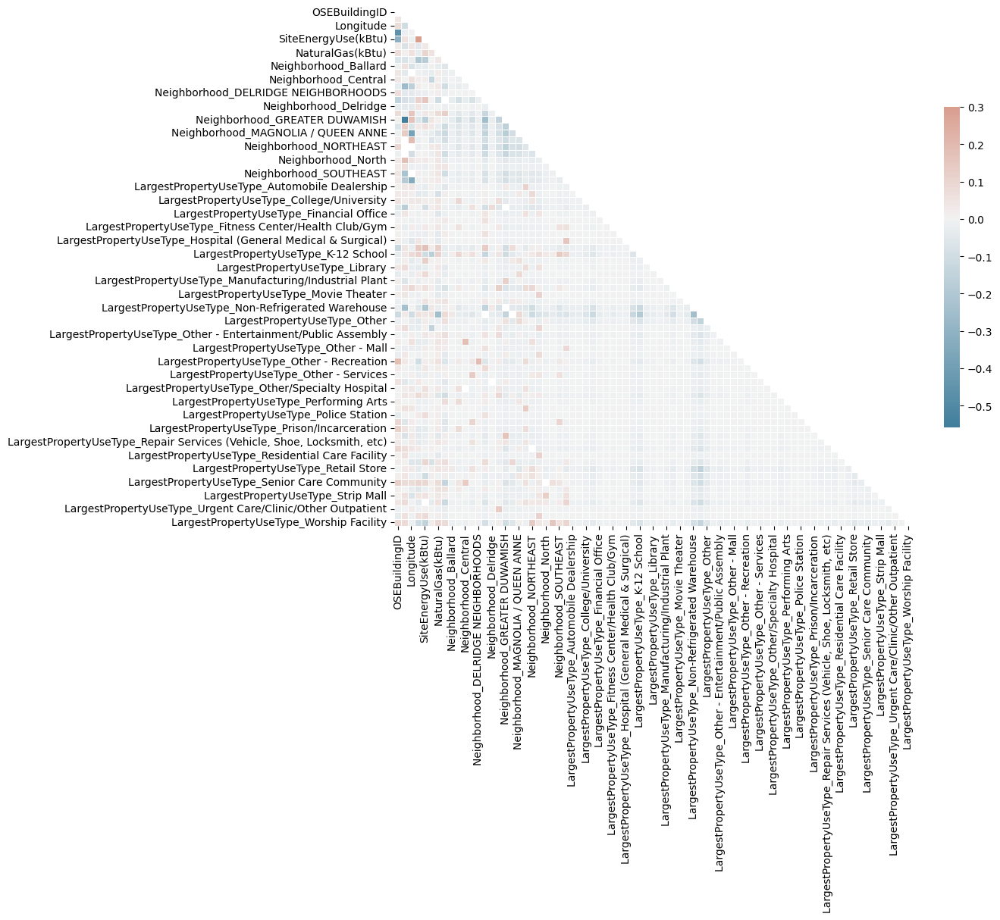

In [11]:
# Compute the correlation matrix
corr = df_encoded.corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 11))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

kot = corr[(corr !=1.00)&((corr>0.5) | (corr<=0.2))]

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(kot, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}
            )

- Neighborhood : Latitude Longitude+
- Age : SteamUse+
- LargestPropertyUseTyp : OSEBuildingID+ Latitude Neighborhood
- LargestPropertyUseTypeGFA : ~SiteEnergyUse(kbtu)--
- SiteEnergyUse(kbtu) : LargestPropertyUseType LargestPropertyUseTypeGFA+
- Steam+/Electricity-/NaturalGas(kbtu)+ : SiteEnergyUse(kbtu) 

#### VIF

In [65]:
#variance_inflation_factor() to calculate the VIF
#https://www.geeksforgeeks.org/python/detecting-multicollinearity-with-vif-python/

from statsmodels.stats.outliers_influence import variance_inflation_factor

df_encoded1=df_encoded.drop(columns=[#'SteamUse(kBtu)',
                                     'Electricity(kBtu)',
                                     'NaturalGas(kBtu)',
                                     #'OSEBuildingID',
                                     # 'Latitude',
                                     # 'Longitude'
                                     ])
X = df_encoded1
# X = df_encoded[['OSEBuildingID','PropertyName',
#                    'Latitude','Longitude',
#                    'Neighborhood',
#                    'Age','LargestPropertyUseType','LargestPropertyUseTypeGFA',
#                    'SiteEnergyUse(kBtu)'
#                    'SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)' 
#                    sont infinis et retirés
#                    ]]

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
print(vif_data.to_string())

'''
VIF Interpretation

    VIF ≈ 1: No correlation with other predictors
    1 < VIF ≤ 5: Mild to moderate correlation (usually fine)
    VIF > 10: Strong multicollinearity -> take corrective steps

'''

                                                                        feature           VIF
0                                                                 OSEBuildingID  4.547295e+00
1                                                                      Latitude  1.163232e+07
2                                                                     Longitude  1.164922e+07
3                                                     LargestPropertyUseTypeGFA  5.905581e+00
4                                                           SiteEnergyUse(kBtu)  5.016015e+00
5                                                                           Age  7.665358e+00
6                                                          Neighborhood_Ballard  1.120671e+00
7                                                          Neighborhood_CENTRAL  2.147047e+00
8                                                          Neighborhood_Central  1.220471e+00
9                                                         Ne

'\nVIF Interpretation\n\n    VIF ≈ 1: No correlation with other predictors\n    1 < VIF ≤ 5: Mild to moderate correlation (usually fine)\n    VIF > 10: Strong multicollinearity -> take corrective steps\n\n'

#### Vif résultat ancien modèle



                     feature            VIF
	0              OSEBuildingID       3.939283
	1               PropertyName       4.000833
	2                   Latitude  949697.482335
	3                  Longitude  948517.546757
	4               Neighborhood       6.799678
	5                        Age       5.732951
	6     LargestPropertyUseType       4.800503
	7  LargestPropertyUseTypeGFA       4.767074
	8        SiteEnergyUse(kBtu)       3.125004

			feature            VIF
	0                   Latitude  948671.419933
	1                  Longitude  947535.082073
	2               Neighborhood       6.799402
	3                        Age       5.525188
	4     LargestPropertyUseType       4.682197
	5  LargestPropertyUseTypeGFA       4.141121
	6        SiteEnergyUse(kBtu)       3.065842


			feature            VIF
	0               Neighborhood  4.263827
	1                        Age  3.170312
	2     LargestPropertyUseType  3.899103
	3  LargestPropertyUseTypeGFA  3.614911
	4        SiteEnergyUse(kBtu)  3.034874


In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


X = df_encoded.drop(columns=['Electricity(kBtu)','NaturalGas(kBtu)'])
# X = df_encoded[['OSEBuildingID','PropertyName',
#                    'Latitude','Longitude',
#                    'Neighborhood',
#                    'Age','LargestPropertyUseType','LargestPropertyUseTypeGFA',
#                    'SiteEnergyUse(kBtu)'
#                    #'SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)' 
#                    # sont infinis et retirés
#                    ]]

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
print(vif_data)

'''
VIF Interpretation

    VIF ≈ 1: No correlation with other predictors
    1 < VIF ≤ 5: Mild to moderate correlation (usually fine)
    VIF > 10: Strong multicollinearity -> take corrective steps

'''

                                              feature           VIF
0                                       OSEBuildingID  4.547295e+00
1                                            Latitude  1.163232e+07
2                                           Longitude  1.164922e+07
3                           LargestPropertyUseTypeGFA  5.905581e+00
4                                 SiteEnergyUse(kBtu)  5.016015e+00
..                                                ...           ...
70                  LargestPropertyUseType_Strip Mall  3.621941e+00
71   LargestPropertyUseType_Supermarket/Grocery Store  2.189385e+01
72  LargestPropertyUseType_Urgent Care/Clinic/Othe...  2.052752e+00
73  LargestPropertyUseType_Wholesale Club/Supercenter  1.542687e+00
74            LargestPropertyUseType_Worship Facility  3.638767e+01

[75 rows x 2 columns]


'\nVIF Interpretation\n\n    VIF ≈ 1: No correlation with other predictors\n    1 < VIF ≤ 5: Mild to moderate correlation (usually fine)\n    VIF > 10: Strong multicollinearity -> take corrective steps\n\n'

### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [129]:
df_m=df_encoded[[#'OSEBuildingID','PropertyName',
                   #'Latitude','Longitude',
                   'Neighborhood',
                   'Age','LargestPropertyUseType','LargestPropertyUseTypeGFA',
                   'SiteEnergyUse(kBtu)'
                   #'SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)' 
                   # sont infinis et retirés
                   ]]



In [83]:
print(df_m.to_string())

      Neighborhood  Age  LargestPropertyUseType  LargestPropertyUseTypeGFA  SiteEnergyUse(kBtu)
0                6   98                      10                    88434.0         7.226362e+06
1                6   29                      10                    83880.0         8.387933e+06
3                6   99                      10                    61320.0         6.794584e+06
4                6   45                      10                   123445.0         1.417261e+07
5                6   26                      35                    88830.0         1.208662e+07
6                6   99                      10                    81352.0         5.758795e+06
7                6   99                      23                   102761.0         6.298132e+06
8                6  121                      10                   163984.0         1.372382e+07
12               6   97                      10                    65009.0         6.596058e+06
14               6  103                 

#### Définition des blocs :

In [70]:
# X = df_encoded[[#'OSEBuildingID','PropertyName',
#                    #'Latitude','Longitude',
#                    'Neighborhood',
#                     'Age',
#                     'LargestPropertyUseType',
#                     'LargestPropertyUseTypeGFA',
#                    #'SiteEnergyUse(kBtu)'
#                     'SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)'                    
#                     ]]

X = df_encoded.drop(columns=["SiteEnergyUse(kBtu)","OSEBuildingID"])
y = df_encoded['SiteEnergyUse(kBtu)']

random_state = 42

#split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)


### Version de test

#### Standardisation

In [71]:
#standardisation
scaler = StandardScaler()
standardized = scaler.fit_transform(X)
#standardized

X = pd.DataFrame(standardized, columns=X.columns)
print(X.to_string())

      Latitude  Longitude  LargestPropertyUseTypeGFA  Electricity(kBtu)  NaturalGas(kBtu)       Age  Neighborhood_Ballard  Neighborhood_CENTRAL  Neighborhood_Central  Neighborhood_DELRIDGE  Neighborhood_DELRIDGE NEIGHBORHOODS  Neighborhood_DOWNTOWN  Neighborhood_Delridge  Neighborhood_EAST  Neighborhood_GREATER DUWAMISH  Neighborhood_LAKE UNION  Neighborhood_MAGNOLIA / QUEEN ANNE  Neighborhood_NORTH  Neighborhood_NORTHEAST  Neighborhood_NORTHWEST  Neighborhood_North  Neighborhood_Northwest  Neighborhood_SOUTHEAST  Neighborhood_SOUTHWEST  LargestPropertyUseType_Automobile Dealership  LargestPropertyUseType_Bank Branch  LargestPropertyUseType_College/University  LargestPropertyUseType_Distribution Center  LargestPropertyUseType_Financial Office  LargestPropertyUseType_Fire Station  LargestPropertyUseType_Fitness Center/Health Club/Gym  LargestPropertyUseType_Food Service  LargestPropertyUseType_Hospital (General Medical & Surgical)  LargestPropertyUseType_Hotel  LargestPropertyUseType_K-

In [74]:
print("means: ", X.sum(axis=0))
print("standard deviations: ", X.std(axis=0).to_string())

means:  Latitude                                                     -3.590550e-11
Longitude                                                    -5.687326e-10
LargestPropertyUseTypeGFA                                     1.136868e-13
Electricity(kBtu)                                             1.918465e-13
NaturalGas(kBtu)                                             -1.065814e-13
                                                                  ...     
LargestPropertyUseType_Strip Mall                             4.263256e-14
LargestPropertyUseType_Supermarket/Grocery Store              9.237056e-14
LargestPropertyUseType_Urgent Care/Clinic/Other Outpatient    1.065814e-14
LargestPropertyUseType_Wholesale Club/Supercenter            -3.552714e-15
LargestPropertyUseType_Worship Facility                      -1.421085e-14
Length: 75, dtype: float64
standard deviations:  Latitude                                                                       1.000347
Longitude                     

In [73]:
modeles=[DummyRegressor,LinearRegression,SVR,RandomForestRegressor]
for modele in modeles:
    model=modele()
    result = cross_validate(model, X_train, y_train, scoring='r2', cv=5)
    print('----------------------------------------------------------------------------------')
    print('Modele:',model)
    print('----------------------------------------------------------------------------------')
    print('fit_time : ',result['fit_time'])
    print('score_time : ',result['score_time'])
    print('test_score : ',result['test_score'])
    print('----------------------------------------------------------------------------------')
    print('fit_time mean : ',result['fit_time'].mean())
    print('score_time mean : ',result['score_time'].mean())
    print('cross test_score mean : ', result['test_score'].mean())
    print('----------------------------------------------------------------------------------')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print( "|R2_score:",r2_score(y_test, y_pred),"|RMSE:",mean_squared_error(y_test, y_pred),"|MAE:", mean_absolute_error(y_test, y_pred),"|" )
print('----------------------------------------------------------------------------------')

----------------------------------------------------------------------------------
Modele: DummyRegressor()
----------------------------------------------------------------------------------
fit_time :  [0.00166464 0.00123024 0.00133801 0.00122905 0.00184298]
score_time :  [0.00076413 0.00053    0.00112677 0.00065279 0.00057483]
test_score :  [-2.99128757e-06 -1.76160784e-03 -1.82278559e-02 -8.80765438e-03
 -3.85651218e-04]
----------------------------------------------------------------------------------
fit_time mean :  0.0014609813690185547
score_time mean :  0.0007297039031982422
cross test_score mean :  -0.0058371521170227595
----------------------------------------------------------------------------------
|R2_score: -0.001235069134486677 |RMSE: 10669359179347.398 |MAE: 2435083.105613701 |
----------------------------------------------------------------------------------
Modele: LinearRegression()
----------------------------------------------------------------------------------


### Résumé des scores de la version de test :

| Modele                | cross fit_time mean   | cross score_time mean | cross test_score mean  | R2_score              | RMSE               | MAE                |
| --------------------- | --------------------- | --------------------- | ---------------------- | --------------------- | ------------------ | ------------------ |
| DummyRegressor        | 0.0011905670166015626 | 0.0006199359893798828 | -0.0058371521170227595 | -0.001235069134486677 | 10669359179347.398 | 2435083.105613701  |
| LinearRegression      | 0.0022328853607177734 | 0.0013867855072021485 | 0.3294379963555233     | 0.34982010314088774   | 6928445741295.873  | 1851818.3787932568 |
| SVR                   | 0.03200850486755371   | 0.016480207443237305  | -0.15068250719403947   | -0.17180837349679856  | 12487022090638.41  | 2269247.1288649766 |
| RandomForestRegressor | 0.3079371452331543    | 0.01009664535522461   | 0.4269649472277727     | 0.47659061328782304   | 5577554079784.284  | 1595758.1092891884 |

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

#### GridSearchCV de test

In [232]:
# CODE OPTIMISATION ET INTERPRETATION DU MODELE
parameters = {
    'n_estimators': [100,200],
    'max_depth': [1,2,3,4,5],
    'max_features':[2,3,4,5]
}
model = RandomForestRegressor(random_state = 808)

scoring = {'r2':'r2', 'mae':'neg_mean_absolute_percentage_error'}
clf = GridSearchCV(model,parameters, cv=5, scoring=scoring, refit='r2')

#clf = GridSearchCV(model, parameters,cv=10,scoring= {'r2':'r2', 'mae':'mean_absolute_percentage_error'})
clf.fit(X_train, y_train)

,estimator,RandomForestR...dom_state=808)
,param_grid,"{'max_depth': [1, 2, ...], 'max_features': [2, 3, ...], 'n_estimators': [100, 200]}"
,scoring,"{'mae': 'neg_mean_absolute_percentage_error', 'r2': 'r2'}"
,n_jobs,None
,refit,'r2'
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [229]:
y_pred_train = clf.predict(X_train)
mean_squared_error(y_train, y_pred_train)


6171519406438.855

In [230]:
results = pd.DataFrame(zip(y_test, y_pred, y_test - y_pred), columns = ['y_test', 'y_pred', 'error'])
results.head(10)

,y_test,y_pred,error
0,1.365659e+07,8.093746e+06,5.562841e+06
1,2.824097e+06,1.768553e+06,1.055544e+06
2,2.177075e+06,1.897873e+06,2.792024e+05
3,2.887392e+06,4.006906e+06,-1.119514e+06
4,1.010968e+06,2.221554e+06,-1.210587e+06
5,2.472350e+06,4.109798e+06,-1.637448e+06
6,9.197463e+05,1.168798e+06,-2.490516e+05
7,1.325973e+06,4.011587e+05,9.248140e+05
8,1.725108e+06,2.577758e+06,-8.526498e+05
9,8.651835e+06,7.928999e+06,7.228358e+05


#### Feature Importances

In [167]:
model=RandomForestRegressor()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
model.fit(X_train, y_train)
print("test :",np.round(model.score(X_test, y_test), 3))
print('train:', np.round(model.score(X_train, y_train), 3))

test : 0.481
train: 0.921


In [168]:
print(model.feature_importances_)



[0.08244872 0.15307431 0.23187802 0.47427566 0.02070616 0.01182115
 0.02579598]


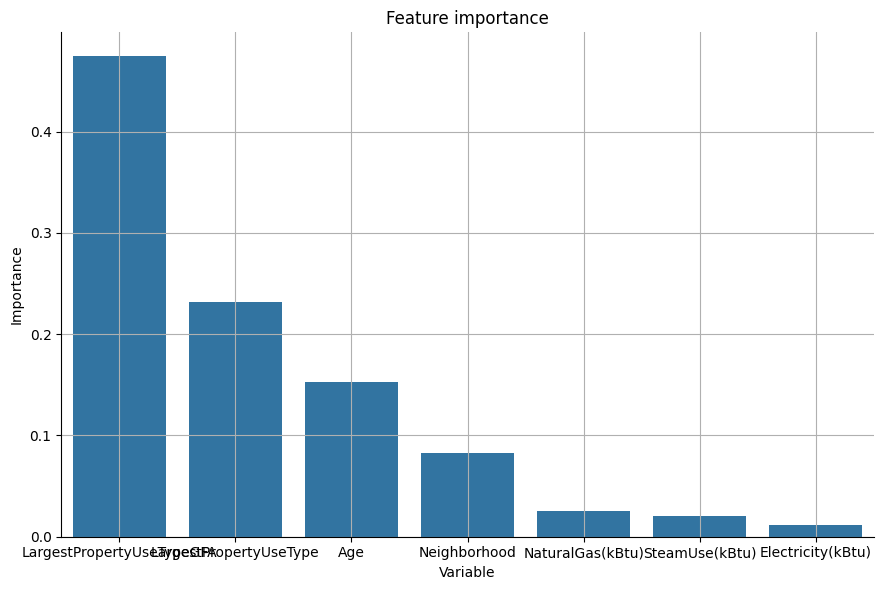

In [ ]:
df = pd.DataFrame()
df['feature'] = X.columns
df['importance'] = model.feature_importances_
df.sort_values(by = 'importance', ascending = False, inplace = True)

fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(1, 1, 1)

sns.barplot(data = df, x='feature', y='importance')
ax.set_title('Feature importance')
ax.set_xlabel('Variable')
ax.set_ylabel('Importance')
ax.grid(True, which = 'both')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()

In [107]:
X = df_encoded[[#'OSEBuildingID','PropertyName',
                   #'Latitude','Longitude',
                   'Neighborhood',
                   'Age',
                   'LargestPropertyUseType','LargestPropertyUseTypeGFA',
                   #'SiteEnergyUse(kBtu)'
                   'SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)'                    
                   ]]
y = df_encoded['SiteEnergyUse(kBtu)']

random_state = 42

#split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

feature_names = [f"feature {i}" for i in range(X.shape[1])]
model=RandomForestRegressor(random_state = 808,max_depth=10)
result = cross_validate(model, X_train, y_train, scoring='r2', cv=10)
print('----------------------------------------------------------------------------------')
print('Modele:',model)
print('----------------------------------------------------------------------------------')
print('fit_time : ',result['fit_time'])
print('score_time : ',result['score_time'])
print('test_score : ',result['test_score'])
print('----------------------------------------------------------------------------------')
print('fit_time mean : ',result['fit_time'].mean())
print('score_time mean : ',result['score_time'].mean())
print('cross test_score mean : ', result['test_score'].mean())
print('----------------------------------------------------------------------------------')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print( "|R2_score:",r2_score(y_test, y_pred),"|RMSE:",mean_squared_error(y_test, y_pred),"|MAE:", mean_absolute_error(y_test, y_pred),"|" )

----------------------------------------------------------------------------------
Modele: RandomForestRegressor(max_depth=10, random_state=808)
----------------------------------------------------------------------------------
fit_time :  [0.27623653 0.246099   0.24385905 0.2451992  0.24735308 0.23557973
 0.2423594  0.24098897 0.24265909 0.24509072]
score_time :  [0.00731564 0.00709224 0.00856948 0.00692582 0.00720239 0.00807142
 0.00715113 0.00729346 0.00765514 0.00688696]
test_score :  [0.35243925 0.48533313 0.52734302 0.43375889 0.39372856 0.52544102
 0.57119139 0.33382849 0.44317149 0.51204378]
----------------------------------------------------------------------------------
fit_time mean :  0.24654247760772705
score_time mean :  0.007416367530822754
cross test_score mean :  0.45782790174389865
----------------------------------------------------------------------------------
|R2_score: 0.4917604087424239 |RMSE: 5415901735223.202 |MAE: 1569164.8344871 |


In [216]:
from sklearn.inspection import permutation_importance
import time

start_time = time.time()
result = permutation_importance(
    model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=feature_names)

Elapsed time to compute the importances: 1.845 seconds


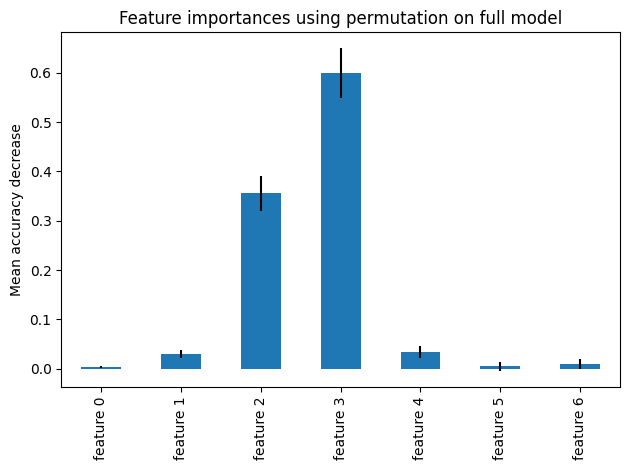

In [217]:
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

#### Modèle gradientBoostingRegressor avec 3 HyperParamètres
- max_depth=2,n_estimators=186,loss='huber'
- Passage du score de 0.51 à 0.57

In [221]:

from sklearn.ensemble import GradientBoostingRegressor

X = df_encoded[[#'OSEBuildingID','PropertyName',
                   #'Latitude','Longitude',
                   'Neighborhood',
                   'Age',
                   'LargestPropertyUseType','LargestPropertyUseTypeGFA',
                   #'SiteEnergyUse(kBtu)'
                   'SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)'                    
                   ]]
y = df_encoded['SiteEnergyUse(kBtu)']

model= GradientBoostingRegressor(random_state=0,max_depth=2,n_estimators=186,loss='huber')
#default value              R2_score: 0.5153880675884466
#optimum:
#   2<depth_max<3           R2_score: 0.5122412441414558
#   150<n_estimators<200    R2_score: 0.553038200593698
#   loss 'huber'            R2_score: 0.5726186726951565
#   learning_rate=0.1       Default
#   subsample=1.0           Default
#   criterion               Default
#   min_samples_split       Default
#   0.001<min_samples_leaf<4
#   min_weight_fraction_leafDefault
#   min_impurity_decrease   Default
#   alpha                   Default
#   max_leaf_nodes          Default ou >100
#   warm_start              Default
#   n_iter_no_change        Default
#   max_features            Default
#   validation_fraction     Default
#   n_iter_no_change        Default


result = cross_validate(model, X_train, y_train, scoring='r2', cv=5)
print('----------------------------------------------------------------------------------')
print('Modele:',model)
print('----------------------------------------------------------------------------------')
print('fit_time : ',result['fit_time'])
print('score_time : ',result['score_time'])
print('test_score : ',result['test_score'])
print('----------------------------------------------------------------------------------')
print('fit_time mean : ',result['fit_time'].mean())
print('score_time mean : ',result['score_time'].mean())
print('cross test_score mean : ', result['test_score'].mean())
print('----------------------------------------------------------------------------------')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print( "|R2_score:",r2_score(y_test, y_pred),"|RMSE:",mean_squared_error(y_test, y_pred),"|MAE:", mean_absolute_error(y_test, y_pred),"|" )

----------------------------------------------------------------------------------
Modele: GradientBoostingRegressor(loss='huber', max_depth=2, n_estimators=186,
                          random_state=0)
----------------------------------------------------------------------------------
fit_time :  [0.4060905  0.38000941 0.38817954 0.37299418 0.38219309]
score_time :  [0.00205112 0.00211    0.00193119 0.00189137 0.00239801]
test_score :  [0.46117713 0.51900741 0.53081092 0.53334327 0.47517743]
----------------------------------------------------------------------------------
fit_time mean :  0.3858933448791504
score_time mean :  0.0020763397216796873
cross test_score mean :  0.5039032345166629
----------------------------------------------------------------------------------
|R2_score: 0.5726186726951565 |RMSE: 4554260061529.187 |MAE: 1443081.6889487721 |


### Version Pipeline

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

'''
df_clean=
    bc_no_housing[['OSEBuildingID','PropertyName',
                    'Latitude','Longitude','Neighborhood',
                    'YearBuilt','LargestPropertyUseType','LargestPropertyUseTypeGFA',
                    'SiteEnergyUse(kBtu)','SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)'
                    ]]
    Sans le type multifamily housing et les outliers
'''
df = df_clean[[#'OSEBuildingID','PropertyName',
                    #'Latitude','Longitude',
                    'Neighborhood',
                    'YearBuilt',
                    'LargestPropertyUseType',
                    'LargestPropertyUseTypeGFA',
                    'SiteEnergyUse(kBtu)',
                    'SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)'
                    ]]

bin_cols = ['SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)']
num_cols = ['LargestPropertyUseTypeGFA']#,'Latitude', 'Longitude', 'SiteEnergyUse(kBtu)']
cat_cols = ['Neighborhood', 'LargestPropertyUseType']
age_col = ['YearBuilt']

def year_to_age(X):
    current_year = pd.Timestamp.today().year
    return (current_year - X).astype(int)

age_transformer = FunctionTransformer(year_to_age)

In [9]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
        ('bin', FunctionTransformer(lambda X: (X > 0).astype(int)), bin_cols),
        ('age', age_transformer, age_col)
    ],
    remainder='drop'
)

In [121]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

#modeles=[DummyRegressor,LinearRegression,SVR,RandomForestRegressor]

for modele in modeles:
    model=modele()

    pipeline = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])

    X = df.drop(columns=['SiteEnergyUse(kBtu)'])   # prédire la consommation totale
    y = df['SiteEnergyUse(kBtu)']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    result = cross_validate(pipeline, X_train, y_train, scoring='r2', cv=5)
    #print('----------------------------------------------------------------------------------')
    #print('Modele:',pipeline)
    print('----------------------------------------------------------------------------------')
    print('fit_time : ',result['fit_time'])
    print('score_time : ',result['score_time'])
    print('test_score : ',result['test_score'])
    print('----------------------------------------------------------------------------------')
    print('fit_time mean : ',result['fit_time'].mean())
    print('score_time mean : ',result['score_time'].mean())
    print('cross test_score mean : ', result['test_score'].mean())
    print('----------------------------------------------------------------------------------')
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    print( "|R2_score:",r2_score(y_test, y_pred),"|RMSE:",mean_squared_error(y_test, y_pred),"|MAE:", mean_absolute_error(y_test, y_pred),"|" )

h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessi

----------------------------------------------------------------------------------
fit_time :  [0.01082015 0.00801206 0.00867605 0.00892949 0.01007652]
score_time :  [0.0071857  0.00586081 0.00693965 0.00602436 0.00746226]
test_score :  [-2.99128757e-06 -1.76160784e-03 -1.82278559e-02 -8.80765438e-03
 -3.85651218e-04]
----------------------------------------------------------------------------------
fit_time mean :  0.009302854537963867
score_time mean :  0.0066945552825927734
cross test_score mean :  -0.0058371521170227595
----------------------------------------------------------------------------------
|R2_score: -0.001235069134486677 |RMSE: 10669359179347.398 |MAE: 2435083.105613701 |
----------------------------------------------------------------------------------
fit_time :  [0.01881003 0.01708913 0.01524782 0.01719904 0.01779771]
score_time :  [0.00807452 0.00605273 0.00674772 0.00694442 0.00650287]
test_score :  [0.4015358  0.52401553 0.52982896 0.46395792 0.49397316]
--------

h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessi

----------------------------------------------------------------------------------
fit_time :  [0.06694031 0.04724765 0.0399096  0.04327202 0.04102325]
score_time :  [0.0177424  0.0114944  0.01128125 0.01201391 0.01198649]
test_score :  [-0.14470767 -0.13246349 -0.21577283 -0.10467031 -0.1559504 ]
----------------------------------------------------------------------------------
fit_time mean :  0.047678565979003905
score_time mean :  0.012903690338134766
cross test_score mean :  -0.1507129368769624
----------------------------------------------------------------------------------
|R2_score: -0.17183992467831422 |RMSE: 12487358306276.977 |MAE: 2269295.945611013 |


h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessi

----------------------------------------------------------------------------------
fit_time :  [0.96090412 0.95343137 0.94190788 0.96564102 0.96992826]
score_time :  [0.0148375  0.01563978 0.01687789 0.01520944 0.01543164]
test_score :  [0.44525168 0.47410033 0.49084061 0.41274584 0.4292442 ]
----------------------------------------------------------------------------------
fit_time mean :  0.9583625316619873
score_time mean :  0.015599250793457031
cross test_score mean :  0.4504365305434984
----------------------------------------------------------------------------------
|R2_score: 0.518610464382468 |RMSE: 5129782224989.972 |MAE: 1472405.4591785355 |


h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


### Résumé des scores par modèles :
|                       | DummyRegressor         | LinearRegression    | SVR                  | RandomForestRegressor |
| --------------------- | ---------------------- | ------------------- | -------------------- | --------------------- |
| cross test_score mean | -0.0058371521170227595 | 0.48266227393282257 | -0.1507129368769624  | 0.4504365305434984    |
| R2_score              | 0.001235069134486677   | 0.5529949773274223  | -0.17183992467831422 | 0.518610464382468     |
| RMSE                  | 10669359179347.398     | 4763374045606.314   | 12487358306276.977   | 5129782224989.972     |
| MAE                   | 2435083.105613701      | 1551642.5501151541  | 2269295.945611013    | 1472405.4591785355    |

Le plus performant est le LinearRegressor

### GridSearch versionPipeline

In [10]:

model=LinearRegression()

pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', model)
])

X = df.drop(columns=['SiteEnergyUse(kBtu)'])   # prédire la consommation totale
y = df['SiteEnergyUse(kBtu)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

result = cross_validate(pipeline, X_train, y_train, scoring='r2', cv=5)
#print('----------------------------------------------------------------------------------')
#print('Modele:',pipeline)
print('----------------------------------------------------------------------------------')
print('fit_time : ',result['fit_time'])
print('score_time : ',result['score_time'])
print('test_score : ',result['test_score'])
print('----------------------------------------------------------------------------------')
print('fit_time mean : ',result['fit_time'].mean())
print('score_time mean : ',result['score_time'].mean())
print('cross test_score mean : ', result['test_score'].mean())
print('----------------------------------------------------------------------------------')
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)


param_grid = {    
    "model__fit_intercept": [True, False],
    "model__positive": [False, True] }

v_scoring = {'r2':'r2','rmse':'neg_root_mean_squared_error', 'mae':'neg_mean_absolute_error'}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring= v_scoring ,#'neg_mean_squared_error',
    refit='r2',
    n_jobs=-1
)
#best_index = grid.best_params_

grid.fit(X, y)

print("\nMeilleur alpha trouvé :", grid.best_params_)

# === 9. Prédiction et métriques finales ===
best_model = grid.best_estimator_
y_pred = best_model.predict(X)

rmse_final = np.sqrt(mean_squared_error(y, y_pred))
mae_final = mean_absolute_error(y, y_pred)
r2_final = r2_score(y, y_pred)

print("\n--- Scores finaux sur tout le dataset ---")
print(f"RMSE : {rmse_final:.2f}")
print(f"MAE  : {mae_final:.2f}")
print(f"R²   : {r2_final:.4f}")

h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\preprocessi

----------------------------------------------------------------------------------
fit_time :  [0.02756572 0.01582694 0.0166707  0.01986456 0.0209651 ]
score_time :  [0.00868773 0.00637317 0.00649452 0.00575519 0.00710797]
test_score :  [0.4015358  0.52401553 0.52982896 0.46395792 0.49397316]
----------------------------------------------------------------------------------
fit_time mean :  0.020178604125976562
score_time mean :  0.0068837165832519535
cross test_score mean :  0.48266227393282257
----------------------------------------------------------------------------------

Meilleur alpha trouvé : {'model__fit_intercept': False, 'model__positive': False}

--- Scores finaux sur tout le dataset ---
RMSE : 2047570.27
MAE  : 1408620.39
R²   : 0.5954


h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
10 fits failed out of a total of 20.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "h:\python_project\Projet3\.venv\Lib\site-packages\sklearn\pipeline.py", line 663, in fit
 

### Résultat :
- Meilleur alpha trouvé : {'model__fit_intercept': False, 'model__positive': False}

--- Scores finaux sur tout le dataset ---
- RMSE : 2047570.27
- MAE  : 1408620.39
- R²   : 0.5954

---

#### Feature importances

In [13]:
def get_feature_importances_linear_pipeline(pipeline):
    """
    Récupère les noms de variables après le preprocessing (ColumnTransformer)
    et les coefficients du LinearRegression du pipeline.
    """
    import numpy as np
    import pandas as pd
    
    preprocessor = pipeline.named_steps["prep"]
    model = pipeline.named_steps["model"]

    feature_names = []

    # Parcourt les transformers du ColumnTransformer
    for name, transformer, cols in preprocessor.transformers_:

        if transformer == "drop":
            continue

        # OneHotEncoder
        if hasattr(transformer, "get_feature_names_out"):
            fn = transformer.get_feature_names_out(cols)

        # Transformers simples : StandardScaler, FunctionTransformer
        else:
            fn = cols

        feature_names.extend(fn)

    # Coefficients du LinearRegression
    coefs = model.coef_.ravel()

    # Création d'un tableau propre
    df_importances = pd.DataFrame({
        "feature": feature_names,
        "coefficient": coefs,
        "importance_abs": np.abs(coefs)
    })

    # Tri décroissant par importance
    df_importances = df_importances.sort_values("importance_abs", ascending=False)

    return df_importances

best_model = grid.best_estimator_

importances_df = get_feature_importances_linear_pipeline(best_model)
print(importances_df.head(20))

                                              feature   coefficient  \
32            LargestPropertyUseType_Lifestyle Center  9.377832e+06   
30                  LargestPropertyUseType_Laboratory  7.729344e+06   
66   LargestPropertyUseType_Supermarket/Grocery Store  7.549104e+06   
53              LargestPropertyUseType_Police Station  7.331892e+06   
68  LargestPropertyUseType_Wholesale Club/Supercenter  6.762841e+06   
60                  LargestPropertyUseType_Restaurant  5.502731e+06   
49    LargestPropertyUseType_Other/Specialty Hospital  4.950839e+06   
46      LargestPropertyUseType_Other - Restaurant/Bar  4.689641e+06   
36                      LargestPropertyUseType_Museum  4.145753e+06   
43                LargestPropertyUseType_Other - Mall  3.149148e+06   
5                 Neighborhood_DELRIDGE NEIGHBORHOODS -2.744028e+06   
40           LargestPropertyUseType_Other - Education  2.640747e+06   
45          LargestPropertyUseType_Other - Recreation  2.588484e+06   
25  La

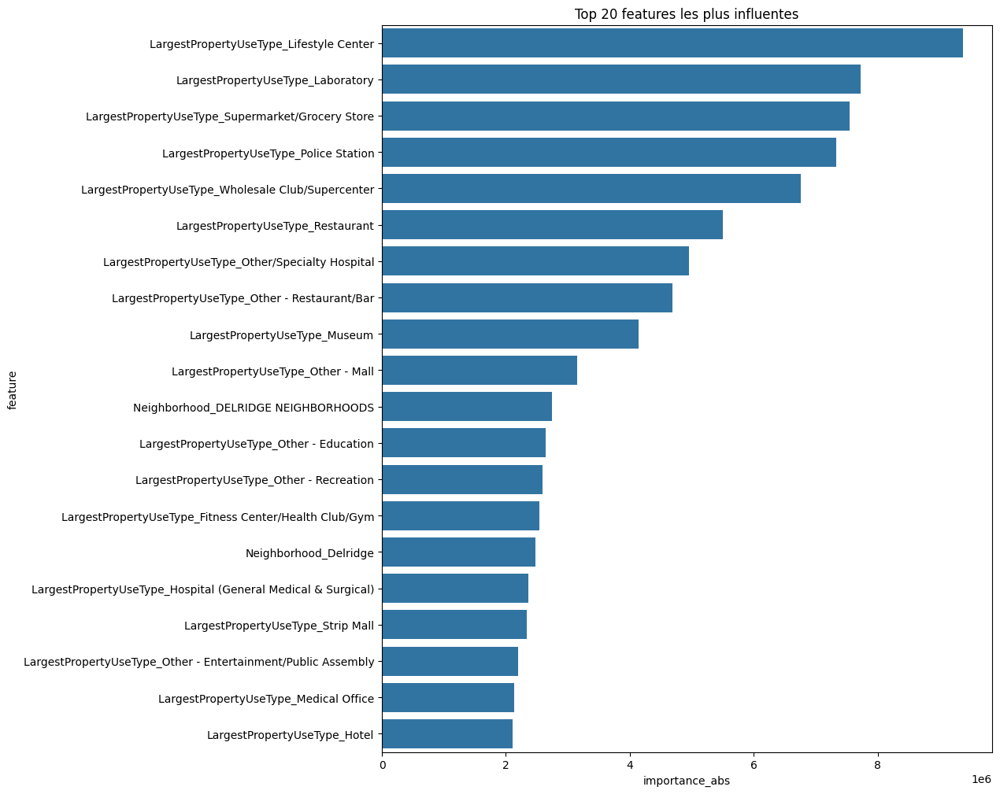

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,12))
sns.barplot(
    data=importances_df.head(20), 
    y="feature", 
    x="importance_abs"
)
plt.title("Top 20 features les plus influentes")
plt.show()

C:\Users\Myself\AppData\Local\Temp\ipykernel_19900\2949014996.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


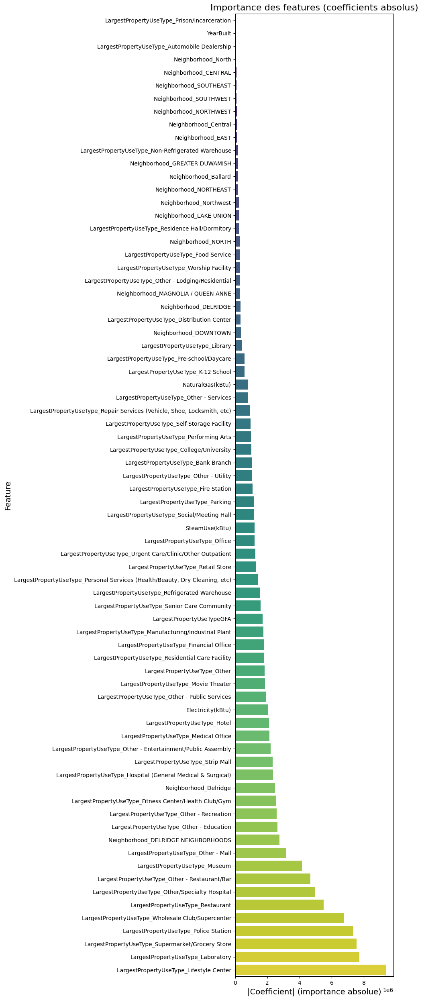

C:\Users\Myself\AppData\Local\Temp\ipykernel_19900\2949014996.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


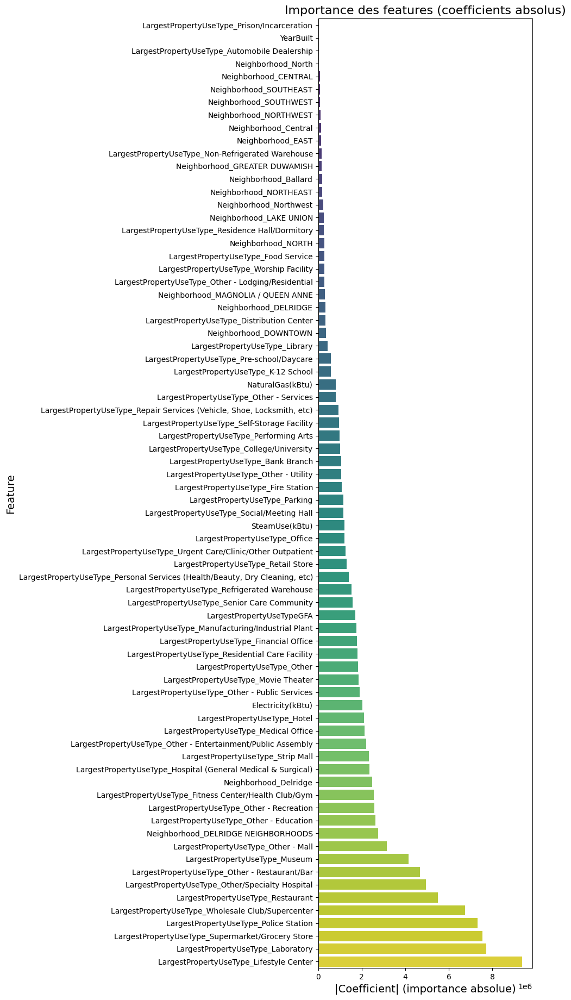

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_all_feature_importances(importances_df, figsize=(10, 25)):
    """
    Affiche un barplot horizontal de toutes les features classées
    par importance absolue (coefficient).
    """

    df_plot = importances_df.sort_values("importance_abs", ascending=True)

    plt.figure(figsize=figsize)
    sns.barplot(
        data=df_plot,
        y="feature",
        x="importance_abs",
        palette="viridis"
    )
    plt.title("Importance des features (coefficients absolus)", fontsize=16)
    plt.xlabel("|Coefficient| (importance absolue)", fontsize=14)
    plt.ylabel("Feature", fontsize=14)
    plt.tight_layout()
    plt.show()


# --- Appel ---
plot_all_feature_importances(importances_df)

figsize = (10, max(12, len(importances_df) * 0.25))
plot_all_feature_importances(importances_df, figsize=figsize)